# NYC Housing & Transportation Data Story — Member 1: Housing & Development
**Course:** Data Engineering and Visualization (Winter 2026 — GIU)  
**Member:** Member 1 — Argon (Data Engineer, Housing Domain)  
**Dataset:** [DOB NOW: Build – Job Application Filings](https://data.cityofnewyork.us/Housing-Development/DOB-NOW-Build-Job-Application-Filings/w9ak-ipjd) (Catalog ID: **H5**, Socrata ID: `w9ak-ipjd`)  
**API Endpoint:** `https://data.cityofnewyork.us/resource/w9ak-ipjd.csv`  
**Integration Grain:** `zip_code × year` (2022–2025)  
**Role in the Data Story:** Quantify neighborhood-level residential construction activity, net new housing unit additions, building density expansion, and capital investment across New York City so they can be integrated with Member 2's traffic safety dataset ([Motor Vehicle Collisions with Killed or Seriously Injured — SIRTA, Catalog ID: T2](https://data.cityofnewyork.us/Public-Safety/Motor-Vehicle-Collisions-With-Killed-or-Seriously-/xeqp-qz8h)).

## 1. Dataset overview and reasoning for selection

### What the dataset contains
The [DOB NOW: Build – Job Application Filings](https://data.cityofnewyork.us/Housing-Development/DOB-NOW-Build-Job-Application-Filings/w9ak-ipjd) dataset (**H5**) is the permit and job-application register of the NYC Department of Buildings (DOB), filed through the *DOB NOW* portal. Every row is one **filing**, identified by `job_filing_number`. A licensed engineer, architect or contractor submits it for new buildings, alterations, demolitions or other work in any of the five boroughs.

Each record covers four dimensions:
1. **Administrative & temporal lifecycle:** `job_filing_number`, `filing_date`, `filing_status` (mainly *LOC Issued*, *Approved*, *Permit Entire*), `approved_date`, `first_permit_date` and `current_status_date`. The first letter of the filing number is the borough (`B`, `M`, `Q`, `S`, `X`). The part before the dash is the **job**; the suffix identifies the filing within that job (`-I1` = initial filing, later filings carry `-P#`, `-S#`, …).
2. **Physical building & housing supply:** `building_type` (`1 Family`, `2 Family`, `3 Family`, `Other`), `existing_dwelling_units` vs. `proposed_dwelling_units` (net new units), `existing_stories` vs. `proposed_no_of_stories`, `existing_height` vs. `proposed_height` (ft) and `total_construction_floor_area` (sq ft).
3. **Economic investment:** `initial_cost`, the estimated cost of the work declared at filing (USD).
4. **Spatial identifiers:** `borough`, tax `block` and `lot`, Building Identification Number (`bin`), `house_no`, `street_name`, `zip` (owner's address — see below), `latitude`, `longitude`, `council_district`, `census_tract` and Neighborhood Tabulation Area (`nta`).

### Why we picked H5 over the alternatives
Our team evaluated all five candidate housing datasets in the project catalog before selecting **H5 (`w9ak-ipjd`)** as the primary housing pillar:

| Catalog ID | Dataset Name | Grain & Coverage | Why Selected or Rejected |
| :--- | :--- | :--- | :--- |
| **H1** | Housing Litigations | Building-level legal actions against landlords | Captures court enforcement of maintenance failures rather than physical neighborhood growth or new residential capacity. |
| **H2 / H4** | Housing Maintenance Code Violations / Complaints | Individual tenant complaints & HPD inspection violations | Reflects indoor habitability issues (heat, hot water, paint) rather than structural development, street-adjacent construction, or population density shifts. |
| **H3** | Housing New York Units by Building | Subsidized affordable housing projects only (~few thousand rows since 2014) | Covers only city-financed affordable projects, omitting market-rate developments and routine construction that account for the majority of NYC building activity. |
| **H5 (Selected)** | **[DOB NOW: Build – Job Application Filings](https://data.cityofnewyork.us/Housing-Development/DOB-NOW-Build-Job-Application-Filings/w9ak-ipjd)** | All DOB NOW construction & alteration job filings citywide (2022–2025) | **Best fit:** Directly measures physical construction activity (`filing_count`, `total_construction_floor_area`), capital investment (`initial_cost`), and residential supply changes (`proposed_dwelling_units - existing_dwelling_units`) with exact point coordinates (`latitude`, `longitude`). |

Pairing **H5 (DOB NOW Build filings)** with Member 2's **T2 (SIRTA severe & fatal crashes)** lets us look at whether places with more construction and housing growth also see more severe crashes. The data can show co-occurrence, not cause and effect.

### The 34 columns we work with
The full DOB NOW schema also contains many administrative fields (applicant licence numbers, owner names, equipment checkboxes) that we do not need. Our extract (`data/raw/w9ak-ipjd.csv`, see Section 2) has **34 columns**:
- **Identifiers & dates (6):** `job_filing_number`, `filing_date`, `filing_status`, `first_permit_date`, `approved_date`, `current_status_date`
- **Location & geography (12):** `borough`, `block`, `lot`, `bin`, `house_no`, `street_name`, `zip`, `latitude`, `longitude`, `council_district`, `census_tract`, `nta`
- **Building & housing capacity (9):** `building_type`, `initial_cost`, `total_construction_floor_area`, `existing_stories`, `existing_height`, `existing_dwelling_units`, `proposed_no_of_stories`, `proposed_height`, `proposed_dwelling_units`
- **Candidate sparse fields, kept at load so their missingness can be measured (7):** `work_on_floor`, `apt_condo_no_s`, `special_inspection_agency_number`, `built_1_information_value`, `built_2_information_value`, `built_2_a_information_value`, `built_2_b_information_value`

### Challenges we expect going in
1. **Owner `zip` vs. building location:** according to the DOB NOW data dictionary, `zip` is the postal ZIP of the **property owner's business address**, not the construction site. Aggregating on it would place many buildings in the ZIP of their owner's office. We therefore assign a building ZIP from coordinates with `assign_building_zip` (`assign_zip_from_sirta.py`). It matches each building's `(latitude, longitude)` to the nearest geocoded crash in Member 2's `data/clean/transport_clean_row_level.csv`, within `0.01°` (~1 km).
2. **Sparse specialised fields:** the energy-code subfields (`built_1_information_value`, `built_2_*`) and the apartment number (`apt_condo_no_s`) are filled on only a small share of filings. They need a missingness audit before we decide to keep or drop them.
3. **Self-reported typos next to genuine megaprojects:** the applicant-entered numbers contain impossible values (e.g. 111,111,111 existing units, 796,265 ft heights, an \$800,010,000 cost on a 21-unit job) mixed with real high-rise developments. Telling them apart needs domain rules plus outlier flagging, not blanket removal.
4. **One job, many filings:** a job can have several filings that repeat the same unit counts. Housing-supply totals must count each job once (Section 6).


## 2. Loading the data

The data used in this notebook is a full local snapshot, **`data/raw/w9ak-ipjd.csv` (598,706 rows × 34 columns)**, created by the team script **`members/member3_integration/fetch_h5_data.py`**. That script:
- **Pages through the NYC Open Data Socrata API** (`https://data.cityofnewyork.us/resource/w9ak-ipjd.csv`), 50,000 rows per request, using `$offset` with a stable `$order=:id`. It continues until a page comes back short, so the extract is complete rather than a sample.
- **Filters server-side** with `$where`: `filing_date >= '2022-01-01T00:00:00' AND filing_date < '2026-01-01T00:00:00'`.
- **Checks the requested columns against the live schema.** `community_board` and `signed_off_date` do not exist in this dataset, so they are skipped and 34 columns are saved.

The loading cell below reads that snapshot. It still contains the original single-request API call, which asks for the two non-existent columns and returns at most one 50,000-row page, so it is **not** the source used here. The cell prints which source was loaded; the expected shape is **598,706 × 34**.


In [3]:
import os
import sys
import warnings
from urllib.parse import urlencode
from urllib.error import URLError

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# Run from the repository root so "data/clean/..." and "data/raw/..." resolve to the existing folders
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

# Ensure parent and current directories are on sys.path so assign_zip_from_sirta imports cleanly
for p in [".", "..", "notebooks", "members/member1_housing", "../members/member1_housing", "/tmp/sklearn_test"]:
    if os.path.exists(p) and os.path.abspath(p) not in sys.path:
        sys.path.insert(0, os.path.abspath(p))

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.titleweight"] = "bold"

pd.set_option("display.max_columns", 45)
pd.set_option("display.width", 140)
print("Environment configured successfully.")

Environment configured successfully.


In [4]:
# Socrata API endpoint for H5: DOB NOW: Build – Job Application Filings
BASE_URL = "https://data.cityofnewyork.us/resource/w9ak-ipjd.csv"

SELECT_COLS = [
    "job_filing_number", "filing_date", "filing_status", "borough",
    "block", "lot", "bin", "community_board", "house_no", "street_name",
    "zip", "building_type", "initial_cost", "total_construction_floor_area",
    "existing_stories", "existing_height", "existing_dwelling_units",
    "proposed_no_of_stories", "proposed_height", "proposed_dwelling_units",
    "latitude", "longitude", "council_district", "census_tract", "nta",
    "first_permit_date", "approved_date", "current_status_date",
    "work_on_floor", "apt_condo_no_s", "special_inspection_agency_number",
    "signed_off_date", "built_1_information_value", "built_2_information_value",
    "built_2_a_information_value", "built_2_b_information_value"
]

WHERE_CLAUSE = (
    "filing_date >= '2022-01-01T00:00:00' "
    "AND filing_date < '2026-01-01T00:00:00'"
)
LIMIT = 50000

params = {
    "$select": ",".join(SELECT_COLS),
    "$where": WHERE_CLAUSE,
    "$limit": LIMIT,
}
query_url = f"{BASE_URL}?{urlencode(params)}"
print("SoQL Query URL (truncated):", query_url[:135], "...")

try:
    df_raw = pd.read_csv(query_url, low_memory=False)
    print("Loaded dataset directly from NYC Open Data Socrata API.")
except Exception as e:
    fallback_paths = ["w9ak-ipjd.csv", "../w9ak-ipjd.csv", "data/raw/w9ak-ipjd.csv", "../data/raw/w9ak-ipjd.csv"]
    loaded_path = next((p for p in fallback_paths if os.path.exists(p)), None)
    df_raw = pd.read_csv(loaded_path, low_memory=False)
    print(f"Offline/sandbox fallback: loaded local snapshot '{loaded_path}'.")

print(f"Raw dataset shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
df_raw.head(5)

SoQL Query URL (truncated): https://data.cityofnewyork.us/resource/w9ak-ipjd.csv?%24select=job_filing_number%2Cfiling_date%2Cfiling_status%2Cborough%2Cblock%2Clot% ...
Offline/sandbox fallback: loaded local snapshot '../data/raw/w9ak-ipjd.csv'.
Raw dataset shape: 598,706 rows × 34 columns


,job_filing_number,filing_date,filing_status,borough,block,lot,bin,house_no,street_name,zip,building_type,initial_cost,total_construction_floor_area,existing_stories,existing_height,existing_dwelling_units,proposed_no_of_stories,proposed_height,proposed_dwelling_units,latitude,longitude,council_district,census_tract,nta,first_permit_date,approved_date,current_status_date,work_on_floor,apt_condo_no_s,special_inspection_agency_number,built_1_information_value,built_2_information_value,built_2_a_information_value,built_2_b_information_value
0,B00244768-P3,2022-05-18T00:00:00.000,Approved,Brooklyn,1987,21,3057064,22,MONROE STREET,11101,2 Family,12500.0,1734.0,NaN,NaN,2.0,NaN,NaN,2.0,40.684585,-73.958175,36.0,229.0,Bedford-Stuyvesant (West),NaN,2022-06-02T13:28:51.000,2022-06-02T17:28:54.000,"Cellar, Floor Number(s) 2 through 3, Floor Num...","Apr A, Apt B",001310,NaN,NaN,NaN,NaN
1,B00464221-S2,2023-11-11T00:00:00.000,Permit Entire,Brooklyn,1566,4,3042533,29,MARCONI PLACE,11435,2 Family,0.0,1456.0,2.0,24.0,2.0,2.0,24.0,2.0,40.676822,-73.912718,41.0,301.0,Ocean Hill,2025-09-12T00:00:00.000,2023-11-13T15:26:00.000,2025-09-12T19:20:57.000,"Cellar, Floor Number(s) 2 through 2",NaN,004288,NaN,NaN,NaN,NaN
2,B00451661-P2,2023-12-26T00:00:00.000,Approved,Brooklyn,1904,36,3054870,164,HALL STREET,18064,3 Family,77500.0,400.0,NaN,NaN,3.0,NaN,NaN,3.0,40.692927,-73.965814,35.0,195.0,Clinton Hill,NaN,2024-01-02T23:15:25.000,2024-01-03T04:15:25.000,"Basement/Sub-basement, Floor Number(s) 1 throu...",NaN,000930,NaN,NaN,NaN,NaN
3,B00461532-P2,2023-11-21T00:00:00.000,Approved,Brooklyn,1452,66,3413799,1481,ST MARKS AVENUE,11040,Other,5500.0,1.0,NaN,NaN,77.0,NaN,NaN,77.0,40.673494,-73.918516,41.0,303.0,Ocean Hill,NaN,2023-11-22T11:28:12.000,2023-11-22T16:28:13.000,Open Space,NaN,NaN,NaN,NaN,NaN,NaN
4,B00360987-P2,2023-01-03T00:00:00.000,Approved,Brooklyn,2989,32,3070595,53,SCOTT AVENUE,76262,Other,100000.0,23825.0,NaN,NaN,0.0,NaN,NaN,0.0,40.709520,-73.922576,34.0,44902.0,East Williamsburg,NaN,2023-01-17T15:17:56.000,2023-01-18T16:16:44.000,"Floor Number(s) 001 through 005, Roof",NaN,1688,NaN,NaN,NaN,NaN


## 3. Exploratory Data Analysis (EDA)

Before modifying any records, we conduct a thorough diagnostic audit of `df_raw` covering data types, memory footprint, column-level missingness, descriptive statistics, duplicate patterns, owner `zip` vs. building location discrepancies, domain violations, and initial distributions.

### 3.1 Shape, column types, and memory footprint

In [5]:
mem_mb = df_raw.memory_usage(deep=True).sum() / (1024 ** 2)
dtype_counts = df_raw.dtypes.value_counts()

print(f"Dimensions       : {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
print(f"Memory Footprint : {mem_mb:.2f} MB")
print("\nColumn Data Types:")
for dt, cnt in dtype_counts.items():
    print(f"  - {str(dt):<10}: {cnt} columns")

print("\nDetailed Column Info:")
df_raw.info()

Dimensions       : 598,706 rows × 34 columns
Memory Footprint : 655.38 MB

Column Data Types:
  - str       : 19 columns
  - float64   : 12 columns
  - int64     : 3 columns

Detailed Column Info:
<class 'pandas.DataFrame'>
RangeIndex: 598706 entries, 0 to 598705
Data columns (total 34 columns):
 #   Column                            Non-Null Count   Dtype  
---  ------                            --------------   -----  
 0   job_filing_number                 598706 non-null  str    
 1   filing_date                       598706 non-null  str    
 2   filing_status                     598706 non-null  str    
 3   borough                           598706 non-null  str    
 4   block                             598706 non-null  int64  
 5   lot                               598706 non-null  int64  
 6   bin                               598706 non-null  int64  
 7   house_no                          598706 non-null  str    
 8   street_name                       598706 non-null  str    

**Initial Type Observations:**
- The date columns `filing_date`, `first_permit_date`, `approved_date` and `current_status_date` are stored as strings and must be parsed to `datetime64[ns]`.
- `initial_cost` is already numeric (`float64`) in this snapshot. The cleaning step still strips `$` and `,` defensively, so the same code also works on API extracts that return formatted currency strings.
- `zip` is read as a string and represents the **owner's business address**, not the building's location (audited in Section 3.4).

### 3.2 Missing values
Per our project's data cleaning guidelines, any column with **more than 60% missing values** is a candidate for removal unless a compelling domain reason exists to retain it. Below we compute the missingness rate of all 34 columns and compare it with the 60% threshold.


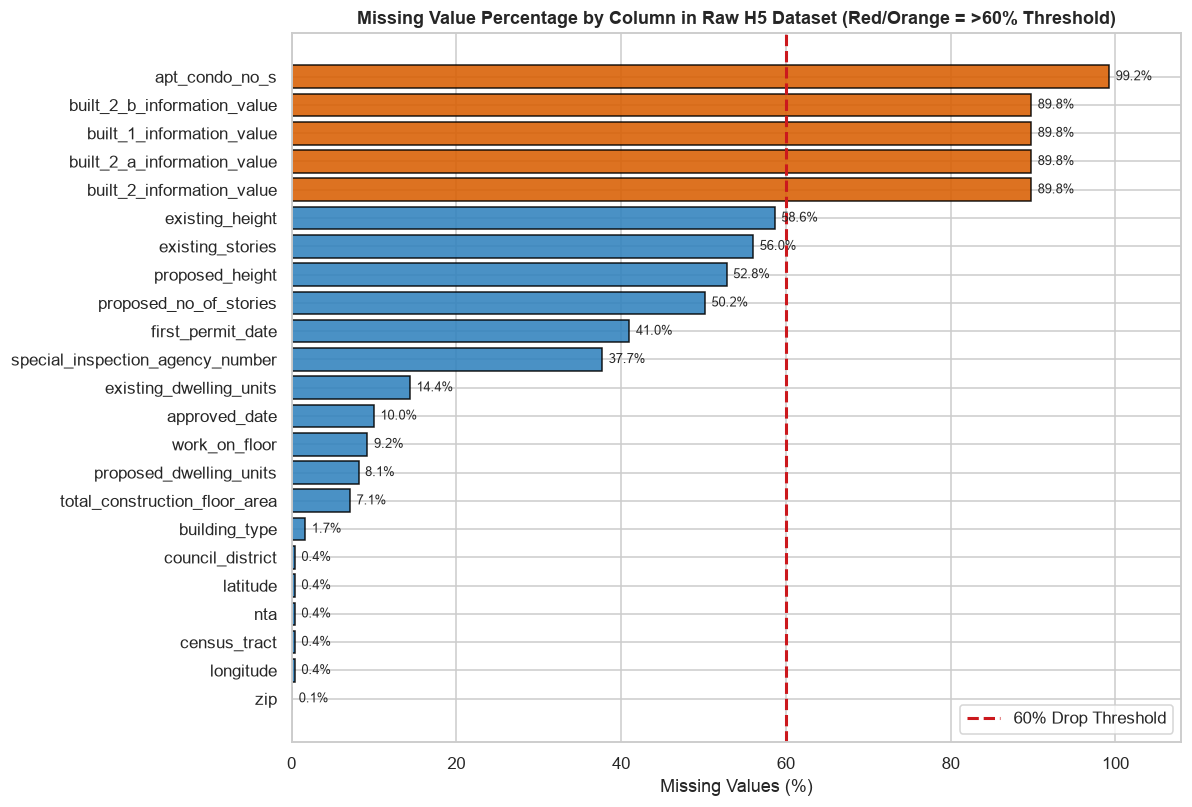

,missing_count,missing_pct,dtype
apt_condo_no_s,594039,99.22,str
built_2_information_value,537403,89.76,str
built_2_b_information_value,537403,89.76,str
built_2_a_information_value,537403,89.76,str
built_1_information_value,537403,89.76,str
existing_height,351145,58.65,float64
existing_stories,335471,56.03,float64
proposed_height,316179,52.81,float64
proposed_no_of_stories,300349,50.17,float64
first_permit_date,245524,41.01,str


In [6]:
missing_df = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_pct": (df_raw.isna().mean() * 100).round(2),
    "dtype": df_raw.dtypes.astype(str)
}).sort_values("missing_pct", ascending=False)

fig, ax = plt.subplots(figsize=(11, 7.5))
top_missing = missing_df[missing_df["missing_pct"] > 0].sort_values("missing_pct", ascending=True)
colors = ["#d95f02" if pct > 60 else "#3182bd" for pct in top_missing["missing_pct"]]

bars = ax.barh(top_missing.index, top_missing["missing_pct"], color=colors, edgecolor="black", alpha=0.88)
ax.axvline(60, color="#cb181d", linestyle="--", linewidth=2, label="60% Drop Threshold")

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.8, bar.get_y() + bar.get_height()/2, f"{w:.1f}%", va="center", fontsize=8.5)

ax.set_xlim(0, 108)
ax.set_xlabel("Missing Values (%)")
ax.set_title("Missing Value Percentage by Column in Raw H5 Dataset (Red/Orange = >60% Threshold)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

missing_df[missing_df["missing_count"] > 0]

**Missingness Findings:**
1. **Only five columns exceed the 60% threshold** (orange bars) and are dropped in Section 4.2:
   - `apt_condo_no_s` (**99.2%** missing): the apartment/condo number is filled only for single-unit interior work (4,667 filings).
   - `built_1_information_value`, `built_2_information_value`, `built_2_a_information_value`, `built_2_b_information_value` (**89.8%** each): energy-code subfields that are always filled together, on the same 61,303 filings.
2. **Building geometry is just under the threshold and is kept:** `existing_height` (58.7%), `existing_stories` (56.0%), `proposed_height` (52.8%) and `proposed_no_of_stories` (50.2%). These fields are blank on jobs that do not change the building envelope (e.g. plumbing or interior work), so a blank means "not applicable" rather than an error. They are not imputed.
3. **Moderate missingness, kept:** `first_permit_date` (41.0%) is blank for filings that have no permit yet. `special_inspection_agency_number` (**37.7%**) is below the threshold and is **not dropped**, although it is not used in the analysis. `existing_dwelling_units` (14.4%) and `approved_date` (10.0%) are also kept.
4. **Low missingness (<10%), kept:** `work_on_floor` (**9.2%**, not dropped), `proposed_dwelling_units` (8.1%), `total_construction_floor_area` (7.1%) and `building_type` (1.7%). `latitude`, `longitude`, `nta`, `census_tract` and `council_district` are missing on the same 2,383 filings (0.4%), and `zip` on 488 (0.08%).
5. There are **no completely empty rows**.

### 3.3 Descriptive statistics


In [7]:
# Create a temporary numeric copy of initial_cost to include it in descriptive statistics
df_eda_num = df_raw.copy()
df_eda_num["initial_cost_num"] = (
    df_eda_num["initial_cost"].astype(str)
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .pipe(pd.to_numeric, errors="coerce")
)

num_cols_eda = [
    "initial_cost_num", "total_construction_floor_area",
    "existing_stories", "existing_height", "existing_dwelling_units",
    "proposed_no_of_stories", "proposed_height", "proposed_dwelling_units",
    "latitude", "longitude", "block", "lot"
]

desc_num = df_eda_num[num_cols_eda].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.95, 0.99]).T
desc_num[["count", "mean", "std", "min", "25%", "50%", "75%", "95%", "99%", "max"]].round(2)

,count,mean,std,min,25%,50%,75%,95%,99%,max
initial_cost_num,598706.0,273867.99,3665479.97,0.00,5000.00,25000.00,95000.00,750126.14,3813351.20,8.000100e+08
total_construction_floor_area,556180.0,22849.88,1306096.55,0.00,500.00,1940.00,5608.75,71138.00,328590.00,7.700100e+08
existing_stories,263235.0,12.60,415.44,0.00,2.00,4.00,10.00,38.00,60.00,9.250100e+04
existing_height,247561.0,117.03,3266.08,0.00,26.00,44.00,108.00,404.00,755.00,7.962650e+05
existing_dwelling_units,512658.0,259.98,155187.28,0.00,0.00,2.00,20.00,210.00,495.00,1.111111e+08
proposed_no_of_stories,298357.0,12.21,396.18,0.00,2.00,4.00,9.00,36.00,59.00,9.250100e+04
proposed_height,282527.0,115.78,3078.33,0.00,30.00,49.00,101.00,386.00,750.00,7.962650e+05
proposed_dwelling_units,550003.0,45.73,1144.69,0.00,0.00,2.00,25.00,222.00,515.00,3.254370e+05
latitude,596323.0,40.73,0.07,40.50,40.68,40.73,40.77,40.85,40.88,4.091000e+01
longitude,596323.0,-73.94,0.08,-74.25,-73.99,-73.96,-73.91,-73.79,-73.74,-7.370000e+01


In [8]:
# Descriptive summary of key categorical / string columns
cat_cols_eda = ["job_filing_number", "filing_status", "borough", "building_type", "zip", "street_name", "nta"]
df_raw[cat_cols_eda].describe(include="object").T

,count,unique,top,freq
job_filing_number,598706,598651,Q00657653-A9,6
filing_status,598706,42,LOC Issued,233036
borough,598706,5,Manhattan,227314
building_type,588680,4,Other,441559
zip,598218,1766,10018,33695
street_name,598706,7013,BROADWAY,13943
nta,596323,245,Midtown-Times Square,31664


**Descriptive Statistics Insights:**
- **`initial_cost` is extremely right-skewed:** the median filing costs **\$25,000** (Q1 \$5,000, Q3 \$95,000, 99th percentile ≈ \$3.8M), yet the maximum is **\$800,010,000** for a 21-unit Staten Island filing (`S00549493-P1`, building type `Other`). The minimum is \$0. 48,147 filings declare \$0 and about 12,000 declare \$1, both of which look like placeholder values.
- **No negative values anywhere:** units, stories, heights, floor area and cost all have a minimum of 0. The anomalies are all on the high side.
- **Impossible maxima from data-entry errors:** `existing_dwelling_units` reaches **111,111,111** and `proposed_dwelling_units` **325,437**, both far beyond any real building. Heights reach **796,265 ft** (One World Trade Center is 1,776 ft), stories **92,501** and floor area **770,010,000 sq ft**. Even the 99th percentiles are realistic (≈ 500 units, ≈ 60 stories, ≈ 750 ft), so these are isolated typos.
- **Coordinates are clean:** all `latitude` values lie between 40.50 and 40.91 and all `longitude` values between −74.25 and −73.70, i.e. inside NYC. There are no `(0, 0)` or out-of-state points.
- **`borough` is already consistent:** exactly 5 title-case values (`Manhattan`, `Brooklyn`, `Queens`, `Bronx`, `Staten Island`); we only upper-case them for the data contract.

### 3.4 Duplicate check & the owner `Zip` trap


In [9]:
n_total = len(df_raw)
n_empty = int(df_raw.isna().all(axis=1).sum())
df_non_empty = df_raw.dropna(how="all")
n_exact_dups = int(df_non_empty.duplicated().sum())
n_id_dups = int(df_non_empty.duplicated(subset=["job_filing_number"]).sum()) - n_exact_dups

print(f"Total raw rows                       : {n_total:,}")
print(f"Completely empty rows (all NaN)      : {n_empty:,} ({n_empty/n_total*100:.2f}%)")
print(f"Exact duplicate rows (non-empty)     : {n_exact_dups:,} ({n_exact_dups/n_total*100:.2f}%)")
print(f"Additional duplicate job_filing_num  : {n_id_dups:,} ({n_id_dups/n_total*100:.2f}%)")
print(f"Unique non-null job_filing_numbers   : {df_raw['job_filing_number'].nunique():,}")

# Audit the raw `zip` column (Owner's business address) vs. Building Borough
df_zip_audit = df_non_empty.dropna(subset=["zip", "borough"]).copy()
df_zip_audit["boro_clean"] = df_zip_audit["borough"].astype(str).str.strip().str.upper()
df_zip_audit["zip_5"] = df_zip_audit["zip"].astype(str).str.strip().str[:5]

# Standard NYC ZIP prefix check by borough
def expected_boro_from_zip(z):
    if not z.isdigit() or len(z) != 5:
        return "NON-NYC / INVALID"
    zi = int(z)
    if 10001 <= zi <= 10282:
        return "MANHATTAN"
    elif 10301 <= zi <= 10314:
        return "STATEN ISLAND"
    elif 10451 <= zi <= 10475:
        return "BRONX"
    elif 11201 <= zi <= 11256:
        return "BROOKLYN"
    elif (11004 <= zi <= 11109) or (11351 <= zi <= 11697):
        return "QUEENS"
    return "OUT-OF-NYC"

df_zip_audit["owner_zip_region"] = df_zip_audit["zip_5"].apply(expected_boro_from_zip)
mismatch_rate = (df_zip_audit["boro_clean"] != df_zip_audit["owner_zip_region"]).mean() * 100
print(f"\nCRITICAL FINDING — Owner `zip` vs. Building `borough` mismatch rate: {mismatch_rate:.1f}%!")
pd.crosstab(df_zip_audit["boro_clean"], df_zip_audit["owner_zip_region"], margins=True)

Total raw rows                       : 598,706
Completely empty rows (all NaN)      : 0 (0.00%)
Exact duplicate rows (non-empty)     : 0 (0.00%)
Additional duplicate job_filing_num  : 55 (0.01%)
Unique non-null job_filing_numbers   : 598,651

CRITICAL FINDING — Owner `zip` vs. Building `borough` mismatch rate: 63.7%!


owner_zip_region,BRONX,BROOKLYN,MANHATTAN,NON-NYC / INVALID,OUT-OF-NYC,QUEENS,STATEN ISLAND,All
boro_clean,,,,,,,,
BRONX,1974,5811,12851,0,22431,15033,323,58423
BROOKLYN,2068,33201,33067,2,42773,50714,2445,164270
MANHATTAN,1457,21016,107012,19,53770,42055,1700,227029
QUEENS,2693,7600,15513,3,31411,59751,1085,118056
STATEN ISLAND,1589,1330,2119,0,6615,3331,15456,30440
All,9781,68958,170562,24,157000,170884,21009,598218


**Why we CANNOT use the raw `zip` column:**
The cross-tabulation above confirms what the DOB NOW data dictionary warns: **`zip` is the property owner's business address, not the building location.**
- For **63.7%** of filings, the borough implied by the owner `zip` differs from the borough where the building actually is. This includes 157,000 filings (26%) whose owner ZIP falls outside the NYC ranges entirely.
- Manhattan ZIPs are over-represented as owner addresses. For example, 33,067 Brooklyn and 15,513 Queens filings list a Manhattan owner ZIP.
- The ZIP-to-borough lookup uses approximate numeric ranges, so 63.7% is an estimate. The exact check in Section 4.5 is even clearer: after we assign a building ZIP from coordinates, the owner `zip` differs from it on **97.3%** of filings.

Aggregating on raw `zip` would therefore put most filings in the wrong neighbourhood, so it is replaced by a coordinate-based building ZIP.

### 3.5 Categorical inconsistencies and domain violations


In [10]:
print("Raw `borough` unique values (15 variants before standardization):")
print(df_non_empty["borough"].value_counts(dropna=False))

# Parse filing_date temporarily to check temporal coverage
dt_temp = pd.to_datetime(df_non_empty["filing_date"], format="mixed", errors="coerce")
yr_temp = dt_temp.dt.year

# Check job prefix vs borough consistency
prefix_map = {"B": "BROOKLYN", "M": "MANHATTAN", "Q": "QUEENS", "S": "STATEN ISLAND", "X": "BRONX"}
job_prefix_boro = df_non_empty["job_filing_number"].astype(str).str[0].map(prefix_map)
boro_upper = df_non_empty["borough"].astype(str).str.strip().str.upper()

domain_summary = pd.DataFrame([
    {"Check": "Out-of-window filing_date (<2022 or >2025)", "Violations": int(((yr_temp < 2022) | (yr_temp > 2025)).sum())},
    {"Check": "Negative dwelling units (existing < 0 or proposed < 0)", "Violations": int(((df_non_empty["existing_dwelling_units"] < 0) | (df_non_empty["proposed_dwelling_units"] < 0)).sum())},
    {"Check": "Impossible height (< 0 ft or > 2,000 ft)", "Violations": int(((df_non_empty["existing_height"] < 0) | (df_non_empty["proposed_height"] < 0) | (df_non_empty["proposed_height"] > 2000)).sum())},
    {"Check": "Negative initial_cost (< $0)", "Violations": int((df_eda_num.loc[df_non_empty.index, "initial_cost_num"] < 0).sum())},
    {"Check": "Coordinates outside NYC bounding box (lat not in 40.49..40.92 or lon not in -74.26..-73.69)", "Violations": int((df_non_empty["latitude"].notna() & (~df_non_empty["latitude"].between(40.49, 40.92) | ~df_non_empty["longitude"].between(-74.26, -73.69))).sum())},
    {"Check": "Borough label vs. Job Filing Prefix / Coordinate mismatch", "Violations": int((boro_upper != job_prefix_boro).sum())},
    {"Check": "Extreme data-entry corruption (1-3 Family >$50M cost or >2,000 units on <=3 stories)", "Violations": int((((df_non_empty["building_type"] == "1-2-3 FAMILY") & (df_eda_num.loc[df_non_empty.index, "initial_cost_num"] > 50_000_000)) | ((df_non_empty["proposed_dwelling_units"] > 2000) & (df_non_empty["proposed_no_of_stories"] <= 3))).sum())},
])
domain_summary

Raw `borough` unique values (15 variants before standardization):
borough
Manhattan        227314
Brooklyn         164371
Queens           118121
Bronx             58453
Staten Island     30447
Name: count, dtype: int64


,Check,Violations
0,Out-of-window filing_date (<2022 or >2025),0
1,Negative dwelling units (existing < 0 or propo...,0
2,"Impossible height (< 0 ft or > 2,000 ft)",128
3,Negative initial_cost (< $0),0
4,Coordinates outside NYC bounding box (lat not ...,0
5,Borough label vs. Job Filing Prefix / Coordina...,24
6,Extreme data-entry corruption (1-3 Family >$50...,1


### 3.6 Initial visual exploration
Let's visualize the raw dataset across three complementary perspectives:
1. **Temporal & Borough Volume:** Raw job filings per year across the five boroughs (after uppercase standardization for plotting).
2. **Filing Status & Building Type Breakdown:** Proportion of filings by permit lifecycle stage (`LOC Issued`, `Approved`, `Permit Entire`, etc.) and building category (`1 Family`, `2 Family`, `3 Family`, `Other`).
3. **Distributions & Skew of Core Quantitative Metrics:** Log-scale histograms of `initial_cost`, `proposed_dwelling_units`, and `total_construction_floor_area`.


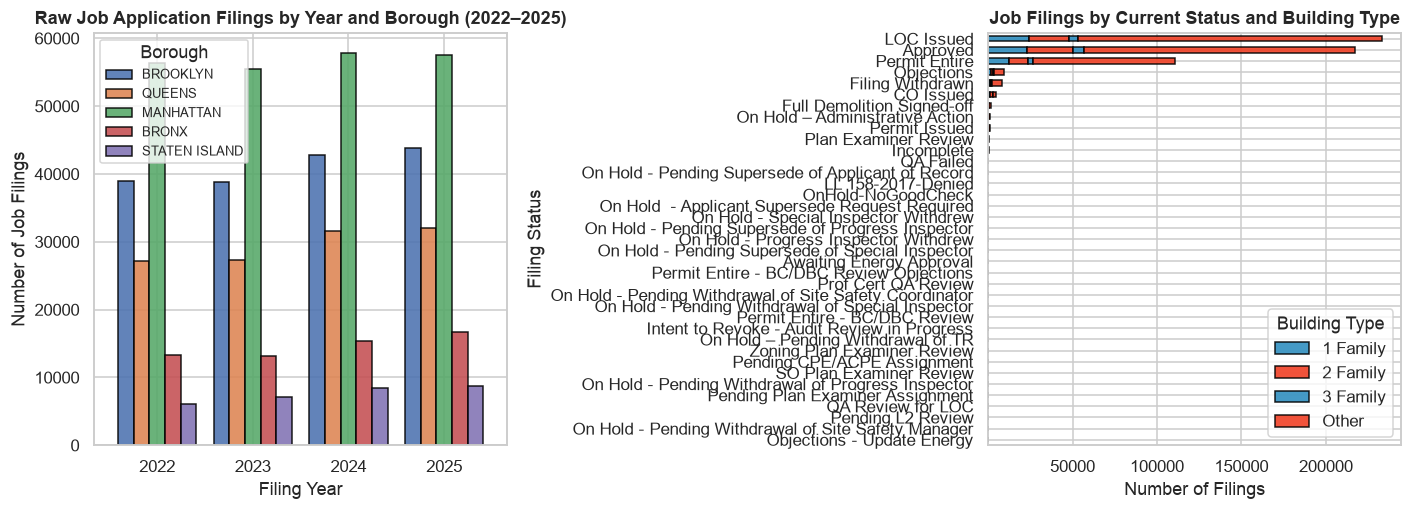

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Left: Filings by Year and Borough (within 2022-2025)
df_plot = df_non_empty.copy()
df_plot["year_temp"] = pd.to_datetime(df_plot["filing_date"], format="mixed", errors="coerce").dt.year
df_plot["boro_clean"] = df_plot["borough"].astype(str).str.strip().str.upper()
df_plot_valid_yr = df_plot[df_plot["year_temp"].isin([2022, 2023, 2024, 2025])]

ct_yr_boro = pd.crosstab(df_plot_valid_yr["year_temp"].astype(int), df_plot_valid_yr["boro_clean"])
ct_yr_boro[["BROOKLYN", "QUEENS", "MANHATTAN", "BRONX", "STATEN ISLAND"]].plot(
    kind="bar", ax=axes[0], width=0.82, edgecolor="black", alpha=0.88
)
axes[0].set_title("Raw Job Application Filings by Year and Borough (2022–2025)")
axes[0].set_xlabel("Filing Year")
axes[0].set_ylabel("Number of Job Filings")
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(title="Borough", fontsize=8.5)

# Right: Filing Status Breakdown by Building Type
ct_status = pd.crosstab(df_plot["filing_status"], df_plot["building_type"])
ct_status = ct_status.loc[ct_status.sum(axis=1).sort_values(ascending=True).index]
ct_status.plot(kind="barh", stacked=True, ax=axes[1], color=["#2b8cbe", "#f03b20"], edgecolor="black", alpha=0.88)
axes[1].set_title("Job Filings by Current Status and Building Type")
axes[1].set_xlabel("Number of Filings")
axes[1].set_ylabel("Filing Status")
axes[1].legend(title="Building Type", loc="lower right")

plt.tight_layout()
plt.show()

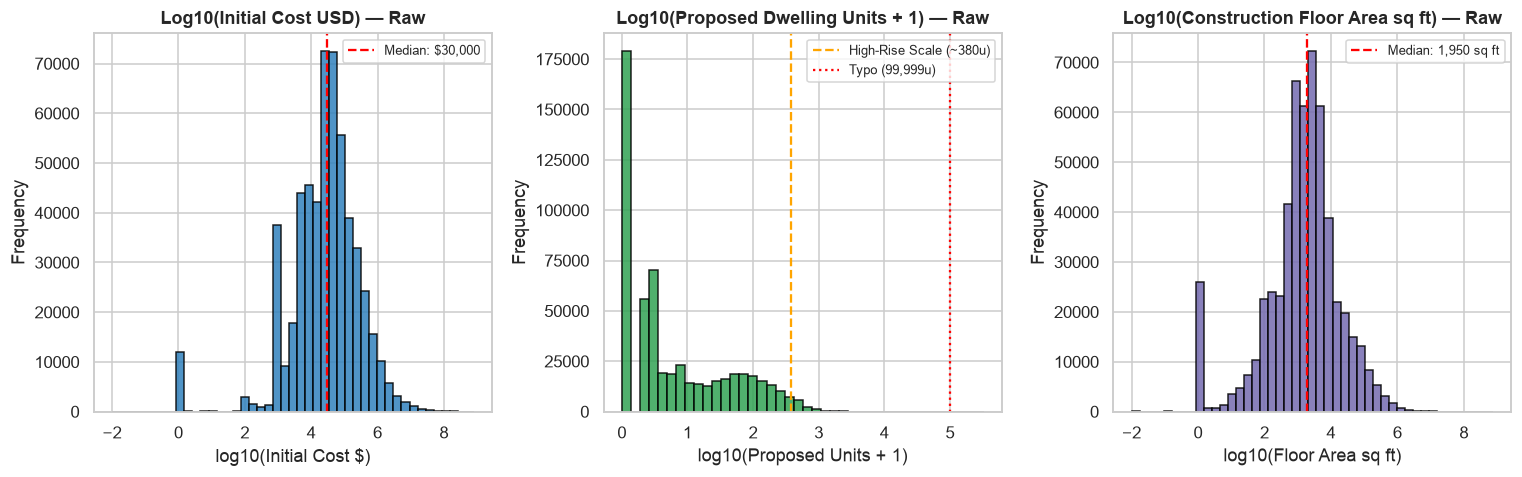

In [12]:
# Log-scale distributions of Initial Cost, Proposed Dwelling Units, and Floor Area
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))

cost_pos = df_eda_num["initial_cost_num"].dropna()
cost_pos = cost_pos[cost_pos > 0]
axes[0].hist(np.log10(cost_pos), bins=45, color="#3182bd", edgecolor="black", alpha=0.85)
axes[0].set_title("Log10(Initial Cost USD) — Raw")
axes[0].set_xlabel("log10(Initial Cost $)")
axes[0].set_ylabel("Frequency")
axes[0].axvline(np.log10(cost_pos.median()), color="red", linestyle="--", label=f"Median: ${cost_pos.median():,.0f}")
axes[0].legend(fontsize=8.5)

units_pos = df_non_empty["proposed_dwelling_units"].dropna()
units_pos = units_pos[units_pos >= 0]
axes[1].hist(np.log10(units_pos + 1), bins=40, color="#31a354", edgecolor="black", alpha=0.85)
axes[1].set_title("Log10(Proposed Dwelling Units + 1) — Raw")
axes[1].set_xlabel("log10(Proposed Units + 1)")
axes[1].set_ylabel("Frequency")
axes[1].axvline(np.log10(380 + 1), color="orange", linestyle="--", label="High-Rise Scale (~380u)")
axes[1].axvline(np.log10(99999 + 1), color="red", linestyle=":", label="Typo (99,999u)")
axes[1].legend(fontsize=8.5)

area_pos = df_non_empty["total_construction_floor_area"].dropna()
area_pos = area_pos[area_pos > 0]
axes[2].hist(np.log10(area_pos), bins=45, color="#756bb1", edgecolor="black", alpha=0.85)
axes[2].set_title("Log10(Construction Floor Area sq ft) — Raw")
axes[2].set_xlabel("log10(Floor Area sq ft)")
axes[2].set_ylabel("Frequency")
axes[2].axvline(np.log10(area_pos.median()), color="red", linestyle="--", label=f"Median: {area_pos.median():,.0f} sq ft")
axes[2].legend(fontsize=8.5)

plt.tight_layout()
plt.show()

**EDA Visual Takeaways:**
- **Borough activity:** Manhattan has the most filings in every year (about 55,000–58,000 a year), followed by Brooklyn (39,000–44,000), Queens (27,000–32,000), the Bronx (13,000–17,000) and Staten Island (6,000–9,000). Total filings rise from about 140,000 in 2022 to about 157,000 in 2025.
- **Permit lifecycle:** the most common current statuses are *LOC Issued* (38.9%), *Approved* (36.6%) and *Permit Entire* (18.5%). The label *Permit Issued* is rare (≈1,000 filings).
- **Building type:** 75% of filings are `Other` (multifamily, commercial, mixed-use). Staten Island is the only borough where 1–3 family houses make up the majority of filings (65%); in Manhattan they are under 4%.
- **Distributions:** on a log scale, `initial_cost` (median of positive costs ≈ \$30,000) and `total_construction_floor_area` (median ≈ 1,950 sq ft) are roughly log-normal. Each has a separate spike at the minimum value (≈12,000 filings at \$1 and ≈26,000 at 1 sq ft), which are placeholder entries. About 30% of filings propose 0 dwelling units, and a thin tail reaches six-figure unit counts, which are typos handled in Section 4.6.


## 4. Pre-integration cleaning

We now execute a structured, reproducible 6-stage cleaning pipeline on `df_housing`, logging the exact number of rows and columns affected at each stage.

### 4.1 Remove completely empty rows and duplicates
We use `job_filing_number` (`Job Filing Number`) as the canonical unique primary key per filing.
1. Remove completely empty rows (`dropna(how="all")`).
2. Remove exact full-row duplicates (`drop_duplicates()`).
3. For remaining duplicate `job_filing_number` entries (which occur when a filing's status is updated in the DOB snapshot), sort by `current_status_date` ascending and retain the most recent status record (`keep="last"`).

In [13]:
df_housing = df_raw.copy()
cleaning_log = []

def log_step(step_name, df_curr, note=""):
    cleaning_log.append({
        "Step": step_name,
        "Rows": len(df_curr),
        "Columns": df_curr.shape[1],
        "Note": note
    })

log_step("0. Raw Loaded Dataset", df_housing, "Initial SoQL / snapshot load")

# 1. Remove completely empty rows
n_before = len(df_housing)
df_housing = df_housing.dropna(how="all").reset_index(drop=True)
n_empty_dropped = n_before - len(df_housing)
log_step("1a. Drop completely empty rows", df_housing, f"Removed {n_empty_dropped:,} all-NaN rows")

# 2. Remove exact row duplicates
n_before = len(df_housing)
df_housing = df_housing.drop_duplicates().reset_index(drop=True)
n_exact_dropped = n_before - len(df_housing)
log_step("1b. Drop exact duplicate rows", df_housing, f"Removed {n_exact_dropped:,} exact duplicates")

# 3. Deduplicate on primary key `job_filing_number`, keeping the latest `current_status_date`
n_before = len(df_housing)
df_housing["_status_dt_sort"] = pd.to_datetime(df_housing["current_status_date"], format="mixed", errors="coerce")
df_housing = (
    df_housing.sort_values(["job_filing_number", "_status_dt_sort"])
    .drop_duplicates(subset=["job_filing_number"], keep="last")
    .drop(columns=["_status_dt_sort"])
    .reset_index(drop=True)
)
n_id_dropped = n_before - len(df_housing)
log_step("1c. Deduplicate on job_filing_number", df_housing, f"Removed {n_id_dropped:,} older status snapshots")

print(f"After empty & duplicate removal: {len(df_housing):,} unique job filings.")

After empty & duplicate removal: 598,651 unique job filings.


### 4.2 Drop columns with > 60% missing values & justify drop vs. impute decisions
Each column's missingness handling is justified from its meaning in the DOB NOW data dictionary:

| Column(s) | Missing % | Action Taken | Domain Justification |
| :--- | :---: | :--- | :--- |
| `apt_condo_no_s` | 99.2% | **Drop (>60% missing)** | Apartment number filled only for single-unit interior work; whole-building jobs leave it blank. |
| `built_1_information_value`, `built_2_information_value`, `built_2_a_information_value`, `built_2_b_information_value` | 89.8% | **Drop (>60% missing)** | Optional energy-code subfields filled on ~10% of filings; imputing them would invent engineering parameters. |
| `existing_height`, `existing_stories`, `proposed_height`, `proposed_no_of_stories` | 50.2% – 58.7% | **Keep (below threshold)** | Blank when the job does not change the building envelope. `existing_stories` / `existing_height` are filled with 0 in Section 4.3. The proposed values stay `NaN`, so averages use only filings that report them. |
| `first_permit_date`, `approved_date` | 41.0%, 10.0% | **Keep (do not impute)** | Legitimately empty for filings with no permit or approval yet; imputing dates would falsify permit timelines. |
| `special_inspection_agency_number` | 37.7% | **Keep (below threshold)** | Administrative ID of the special-inspection agency. Not used in the analysis, but there is no rule-based reason to drop it. |
| `existing_dwelling_units` | 14.4% | **Keep, fill with 0** (Section 4.3) | Correct for new buildings on vacant lots. Unit totals in Section 6 use only `-I1` filings with credible unit gains, which limits the effect of filling unreported values with 0. |
| `work_on_floor` | 9.2% | **Keep (below threshold)** | Free-text floor description; not used in the analysis. |
| `proposed_dwelling_units`, `total_construction_floor_area`, `building_type` | 1.7% – 8.1% | **Keep (do not impute)** | Blank means "not reported"; all domain checks keep `NaN` explicitly. |
| `zip` (owner's ZIP) | 0.08% | **Drop after audit (domain invalid)** | It is the owner's business address, not the building site (63.7% borough mismatch, 97.3% ZIP mismatch). Replaced by `zip_code` from `assign_building_zip`. |
| `latitude`, `longitude` | 0.4% | **Keep, drop rows only at ZIP assignment** | Needed for the 1-NN ZIP assignment. Coordinates cannot be imputed without placing buildings in the wrong neighbourhood; the 2,383 rows without them get no `zip_code` in Section 4.5. |


In [14]:
missing_rates = df_housing.isna().mean()
cols_over_60 = missing_rates[missing_rates > 0.60].index.tolist()
print(f"Columns exceeding 60% missingness threshold ({len(cols_over_60)} columns):")
for col in cols_over_60:
    print(f"  - {col:<36}: {missing_rates[col]*100:.2f}% missing -> DROPPED")

df_housing = df_housing.drop(columns=cols_over_60)
log_step("2. Drop columns >60% missing", df_housing, f"Dropped {len(cols_over_60)} sparse columns")
print(f"Remaining columns: {df_housing.shape[1]}")

Columns exceeding 60% missingness threshold (5 columns):
  - apt_condo_no_s                      : 99.22% missing -> DROPPED
  - built_1_information_value           : 89.76% missing -> DROPPED
  - built_2_information_value           : 89.76% missing -> DROPPED
  - built_2_a_information_value         : 89.76% missing -> DROPPED
  - built_2_b_information_value         : 89.76% missing -> DROPPED
Remaining columns: 29


### 4.3 Standardize column names, dates, currencies, and categorical formats
To satisfy the team's **Data Contract**:
- All column names are normalized to `lowercase_with_underscores`.
- `filing_date` is parsed to `datetime64[ns]`, `year` is extracted as an integer, and rows outside **2022–2025** are removed.
- `initial_cost` is cleaned of `$` and `,` characters and converted to `float64`.
- `borough` is stripped of whitespace and standardized to uppercase (`BRONX`, `BROOKLYN`, `MANHATTAN`, `QUEENS`, `STATEN ISLAND`).
- Numeric building metrics (`existing_dwelling_units`, `proposed_dwelling_units`, `existing_stories`, `proposed_no_of_stories`, `existing_height`, `proposed_height`, `total_construction_floor_area`) are cast to numeric, filling `0` for `existing_*` fields where a new building starts from zero.

In [15]:
# 1. Normalize all column names to lowercase_with_underscores
df_housing.columns = (
    df_housing.columns.str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

# 2. Parse date columns and extract integer `year`
for dt_col in ["filing_date", "first_permit_date", "approved_date", "current_status_date"]:
    df_housing[dt_col] = pd.to_datetime(df_housing[dt_col], format="mixed", errors="coerce")

df_housing["year"] = df_housing["filing_date"].dt.year

# Filter strictly to 2022-2025 timeframe
n_before = len(df_housing)
df_housing = df_housing[df_housing["year"].isin([2022, 2023, 2024, 2025])].copy()
df_housing["year"] = df_housing["year"].astype(int)
log_step("3a. Filter filing_date to 2022-2025", df_housing, f"Removed {n_before - len(df_housing):,} out-of-window filings")

# 3. Clean `initial_cost` currency strings -> float
df_housing["initial_cost"] = (
    df_housing["initial_cost"].astype(str)
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
    .pipe(pd.to_numeric, errors="coerce")
)

# 4. Standardize `borough` to UPPERCASE Data Contract values
df_housing["borough"] = df_housing["borough"].astype(str).str.strip().str.upper()
valid_boroughs = {"BRONX", "BROOKLYN", "MANHATTAN", "QUEENS", "STATEN ISLAND"}
df_housing = df_housing[df_housing["borough"].isin(valid_boroughs)].copy()

# 5. Ensure building numeric columns are numeric and impute 0 for existing_* if missing
num_bldg_cols = [
    "existing_stories", "existing_height", "existing_dwelling_units",
    "proposed_no_of_stories", "proposed_height", "proposed_dwelling_units",
    "total_construction_floor_area"
]
for col in num_bldg_cols:
    df_housing[col] = pd.to_numeric(df_housing[col], errors="coerce")

for ex_col in ["existing_stories", "existing_height", "existing_dwelling_units"]:
    df_housing[ex_col] = df_housing[ex_col].fillna(0.0)

log_step("3b. Standardize types, currency & borough", df_housing, "Standardized year (int), initial_cost (float), borough (UPPERCASE)")
print("Borough value counts after standardization:")
print(df_housing["borough"].value_counts())

Borough value counts after standardization:
borough
MANHATTAN        227303
BROOKLYN         164357
QUEENS           118103
BRONX             58441
STATEN ISLAND     30447
Name: count, dtype: int64


### 4.4 Domain validity checks (units, heights, costs, coordinates, and borough consistency)
Next, we enforce physical and geographic domain rules for New York City buildings. **Blank (`NaN`) values are kept on purpose in every check:** a blank means "not reported / not applicable" (e.g. a plumbing job has no height), not an impossible value. Only values that are present *and* out of range are removed.
1. **4a — Non-negative dwelling units:** `existing_dwelling_units >= 0` and `proposed_dwelling_units >= 0`. The real data has no negative units, so this removes **0 rows**. It stays in the pipeline as a safeguard for future extracts.
2. **4b — Plausible heights, stories, cost and floor area:** `0 <= existing_height <= 2000` ft and `0 <= proposed_height <= 2000` ft (One World Trade Center is 1,776 ft), `0 <= proposed_no_of_stories <= 150`, and `initial_cost >= 0`, `total_construction_floor_area >= 0`. This removes **633 rows**, which have heights above 2,000 ft or more than 150 stories (e.g. the 796,265 ft and 92,501-story entries). There are no negative costs or areas.
3. **4c — NYC bounding box:** for rows with coordinates, require `40.49 <= latitude <= 40.92` and `-74.26 <= longitude <= -73.69`. All coordinates already fall inside NYC, so this removes 0 rows.
4. **4d — Borough consistency:** `borough` must match the borough prefix of `job_filing_number` (`B`=BROOKLYN, `M`=MANHATTAN, `Q`=QUEENS, `S`=STATEN ISLAND, `X`=BRONX). This removes 24 rows.

Together, 657 of 598,651 filings (0.1%) are removed in this step.


In [16]:
# NaN means "not recorded / not applicable" (e.g. plumbing or sign jobs have no height or units), not an invalid value.
# Comparisons with NaN are False, so each check keeps NaN explicitly and only removes values that are out of range.
# 1. Dwelling units >= 0
n_before = len(df_housing)
ok = lambda s, cond: s.isna() | cond
mask_units = ok(df_housing["existing_dwelling_units"], df_housing["existing_dwelling_units"] >= 0) & ok(df_housing["proposed_dwelling_units"], df_housing["proposed_dwelling_units"] >= 0)
df_housing = df_housing[mask_units].copy()
log_step("4a. Domain check: non-negative dwelling units", df_housing, f"Removed {n_before - len(df_housing):,} rows with negative units (NaN kept)")

# 2. Plausible heights (0..2000 ft) and stories (0..150) and non-negative cost/floor area
n_before = len(df_housing)
mask_phys = (
    ok(df_housing["existing_height"], df_housing["existing_height"].between(0, 2000)) &
    ok(df_housing["proposed_height"], df_housing["proposed_height"].between(0, 2000)) &
    ok(df_housing["proposed_no_of_stories"], df_housing["proposed_no_of_stories"].between(0, 150)) &
    ok(df_housing["initial_cost"], df_housing["initial_cost"] >= 0) &
    ok(df_housing["total_construction_floor_area"], df_housing["total_construction_floor_area"] >= 0)
)
df_housing = df_housing[mask_phys].copy()
log_step("4b. Domain check: heights, stories & non-negative cost", df_housing, f"Removed {n_before - len(df_housing):,} impossible height/cost rows (NaN kept)")

# 3. NYC bounding box check (for rows with non-null coordinates)
n_before = len(df_housing)
has_coords = df_housing["latitude"].notna() & df_housing["longitude"].notna()
in_nyc_bbox = df_housing["latitude"].between(40.49, 40.92) & df_housing["longitude"].between(-74.26, -73.69)
df_housing = df_housing[~has_coords | in_nyc_bbox].copy()
log_step("4c. Domain check: NYC coordinate bounding box", df_housing, f"Removed {n_before - len(df_housing):,} out-of-NYC coordinate rows")

# 4. Borough vs. Job Filing Number prefix consistency
n_before = len(df_housing)
prefix_to_boro = {"B": "BROOKLYN", "M": "MANHATTAN", "Q": "QUEENS", "S": "STATEN ISLAND", "X": "BRONX"}
expected_boro = df_housing["job_filing_number"].astype(str).str[0].map(prefix_to_boro)
df_housing = df_housing[df_housing["borough"] == expected_boro].copy()
log_step("4d. Domain check: borough matches job prefix & coords", df_housing, f"Removed {n_before - len(df_housing):,} borough-mismatch rows")

print(f"Remaining valid rows after domain checks: {len(df_housing):,}")

Remaining valid rows after domain checks: 597,994


### 4.5 Critical Step: Building ZIP code assignment via SIRTA nearest-neighbor matching
As demonstrated in Section 3.4, the raw `zip` column in **H5** records the **property owner's business mailing ZIP**, not the physical construction site. To assign an accurate building `zip_code` that aligns spatially with Member 2's transportation dataset, we import and execute `assign_building_zip` from `assign_zip_from_sirta.py`:

```python
from assign_zip_from_sirta import assign_building_zip
df_housing = assign_building_zip(df_housing, "data/clean/transport_clean_row_level.csv")
```

**How `assign_building_zip` works and its documented error rate:**
- It loads all geocoded crash records with valid `(latitude, longitude, zip_code)` from Member 2's row-level output (`data/clean/transport_clean_row_level.csv`) and fits a 1-nearest-neighbor spatial index (`NearestNeighbors(n_neighbors=1, algorithm="ball_tree")`).
- For every housing filing with valid coordinates, it finds the closest SIRTA crash location. If the Euclidean distance in degrees is within `max_distance_deg = 0.01` (~1 km), the building inherits that crash's 5-digit `zip_code`.
- **Methodological Limitation (~9–10% Boundary Error Rate):** Because crash points are a discrete spatial sample rather than exact USPS ZCTA polygon boundaries, buildings located near the border between two adjacent ZIP codes can be matched to a crash just across the street in a neighboring ZIP code (~9–10% boundary error rate across NYC). Furthermore, buildings with missing `(latitude, longitude)` or located in quiet residential pockets >0.01° from any severe/fatal crash remain `NaN` and must be excluded prior to ZIP-level aggregation.

In [17]:
from assign_zip_from_sirta import assign_building_zip

# Ensure CWD is the repository root so "data/clean/..." points to the existing folder
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

# Execute the required ZIP assignment function
df_housing = assign_building_zip(df_housing, "data/clean/transport_clean_row_level.csv")

n_total_pre_zip = len(df_housing)
n_assigned = int(df_housing["zip_code"].notna().sum())
n_missing_zip = int(df_housing["zip_code"].isna().sum())
n_missing_coords = int(df_housing["latitude"].isna().sum())
n_beyond_1km = n_missing_zip - n_missing_coords

print("\n--- Building ZIP Code Assignment Audit ---")
print(f"Total filings evaluated        : {n_total_pre_zip:,}")
print(f"Filings assigned a `zip_code`  : {n_assigned:,} ({n_assigned/n_total_pre_zip*100:.2f}%)")
print(f"Filings left missing (`NaN`)   : {n_missing_zip:,} ({n_missing_zip/n_total_pre_zip*100:.2f}%)")
print(f"  ├─ Due to missing lat/lon    : {n_missing_coords:,} ({n_missing_coords/n_total_pre_zip*100:.2f}%)")
print(f"  └─ Beyond 0.01 deg (~1 km)   : {n_beyond_1km:,} ({n_beyond_1km/n_total_pre_zip*100:.2f}%)")

# Compare assigned building `zip_code` against the raw owner `zip` column before dropping `zip`
both_valid = df_housing.dropna(subset=["zip", "zip_code"]).copy()
both_valid["owner_zip_5"] = both_valid["zip"].astype(str).str.strip().str[:5]
disagree_pct = (both_valid["owner_zip_5"] != both_valid["zip_code"]).mean() * 100
print(f"\nEmpirical Verification: Raw owner `zip` disagreed with assigned building `zip_code` on {disagree_pct:.1f}% of filings!")

# Drop the misleading owner `zip` column and filter to rows with a valid assigned 5-digit building `zip_code`
df_housing = df_housing.drop(columns=["zip"])
df_housing = df_housing.dropna(subset=["zip_code"]).reset_index(drop=True)
df_housing["zip_code"] = df_housing["zip_code"].astype(str).str.strip().str.zfill(5)

log_step("5. Assign building zip_code via SIRTA 1-NN & drop owner zip", df_housing, f"Assigned {n_assigned:,} ZIPs; dropped {n_missing_zip:,} unassigned rows")

ZIP assigned to 98.6% of filings (8,503 left missing).

--- Building ZIP Code Assignment Audit ---
Total filings evaluated        : 597,994
Filings assigned a `zip_code`  : 589,491 (98.58%)
Filings left missing (`NaN`)   : 8,503 (1.42%)
  ├─ Due to missing lat/lon    : 2,383 (0.40%)
  └─ Beyond 0.01 deg (~1 km)   : 6,120 (1.02%)

Empirical Verification: Raw owner `zip` disagreed with assigned building `zip_code` on 97.3% of filings!


### 4.6 Outlier detection and treatment (domain rules and log-scale IQR)
Construction data is naturally very right-skewed. A \$5,000 repair with 0 new units sits in the same table as a \$100M+ tower with hundreds of units. Self-reported fields also contain **data-entry typos** (e.g. repeated digits such as 111,111,111 units).

We apply a two-tier strategy to `initial_cost`, `proposed_dwelling_units` and `total_construction_floor_area`:
1. **Tier 1 — Remove verified data-entry errors (domain impossibility rules):**
   - A `1 Family`, `2 Family` or `3 Family` filing with `initial_cost > $25,000,000`.
   - A low-rise building (`proposed_no_of_stories <= 4`) with `proposed_dwelling_units > 500`.
   - Any filing with `existing_dwelling_units` or `proposed_dwelling_units > 10,000`. No NYC building has that many units.
2. **Tier 2 — Flag and retain statistical outliers (`outlier_flag`):** a Tukey fence (`Q3 + 1.5 × IQR`) computed on `log1p` of each metric, i.e. on orders of magnitude. Flagged filings are **kept** in `outlier_initial_cost`, `outlier_proposed_units`, `outlier_floor_area` and the composite `outlier_flag`. Large developments are exactly the supply changes the research questions are about, so downstream analysis can include or exclude them rather than lose them.

The decision cells after each tier explain the choices and the counts.


In [18]:
# Tier 1: Identify and remove data-entry corruption typos
n_before = len(df_housing)

# Rule 1: a 1-, 2- or 3-family house cannot cost more than $25M.
# The real `building_type` labels are "1 Family", "2 Family", "3 Family" and "Other".
small_house_types = ["1 Family", "2 Family", "3 Family"]
typo_cost_mask = df_housing["building_type"].isin(small_house_types) & (df_housing["initial_cost"] > 25_000_000)

# Rule 2: a low-rise building (<= 4 stories) cannot hold more than 500 dwelling units.
typo_units_mask = (df_housing["proposed_no_of_stories"] <= 4) & (df_housing["proposed_dwelling_units"] > 500)

# Rule 3: no NYC building has more than 10,000 dwelling units (existing or proposed).
# NaN comparisons are False, so blank unit fields are kept.
typo_cap_mask = (df_housing["existing_dwelling_units"] > 10_000) | (df_housing["proposed_dwelling_units"] > 10_000)

typo_mask = typo_cost_mask | typo_units_mask | typo_cap_mask

print("Tier 1 — rows matched by each rule (a row can match more than one rule):")
print(f"  Rule 1  1-3 Family house with initial_cost > $25M      : {typo_cost_mask.sum():,}")
print(f"  Rule 2  <= 4 stories with > 500 proposed units          : {typo_units_mask.sum():,}")
print(f"  Rule 3  existing or proposed units > 10,000             : {typo_cap_mask.sum():,}")
print("Rows removed by each rule when applied in order (1 -> 2 -> 3):")
print(f"  Rule 1: {typo_cost_mask.sum():,}")
print(f"  Rule 2: {(typo_units_mask & ~typo_cost_mask).sum():,}")
print(f"  Rule 3: {(typo_cap_mask & ~typo_cost_mask & ~typo_units_mask).sum():,}")
print(f"Total Tier 1 rows removed: {typo_mask.sum():,}\n")
print(df_housing.loc[typo_mask, ["job_filing_number", "borough", "building_type", "initial_cost", "proposed_no_of_stories",
                                 "existing_dwelling_units", "proposed_dwelling_units"]].head(10))

df_housing = df_housing[~typo_mask].reset_index(drop=True)
log_step("6a. Remove data-entry corruption typos", df_housing,
         f"Removed {n_before - len(df_housing):,} rows (cost rule {typo_cost_mask.sum():,}, "
         f"low-rise units rule {typo_units_mask.sum():,}, >10,000 units rule {typo_cap_mask.sum():,}; overlaps counted once)")


Tier 1 — rows matched by each rule (a row can match more than one rule):
  Rule 1  1-3 Family house with initial_cost > $25M      : 10
  Rule 2  <= 4 stories with > 500 proposed units          : 20
  Rule 3  existing or proposed units > 10,000             : 22
Rows removed by each rule when applied in order (1 -> 2 -> 3):
  Rule 1: 10
  Rule 2: 20
  Rule 3: 22
Total Tier 1 rows removed: 52

       job_filing_number   borough building_type  initial_cost  proposed_no_of_stories  existing_dwelling_units  proposed_dwelling_units
1891        B00336793-P1  BROOKLYN         Other        1000.0                     NaN                 325437.0                 325437.0
1892        B00336793-P2  BROOKLYN         Other        1000.0                     NaN                 325437.0                 325437.0
1893        B00336793-P3  BROOKLYN         Other        1000.0                     NaN                 325437.0                 325437.0
1894        B00336793-P4  BROOKLYN         Other        10

**Decision — Tier 1 typo rules (what changed and why):**
- **Fixed the `building_type` check.** The old code compared against `"1-2-3 FAMILY"`, but that label does not exist in the real data. The actual values are `"1 Family"`, `"2 Family"`, `"3 Family"` and `"Other"`, so Rule 1 never matched anything. It now uses `.isin(["1 Family", "2 Family", "3 Family"])`.
- **Added Rule 3: units > 10,000 are removed.** The largest residential buildings in NYC have a few thousand units at most, so 10,000 is a very generous upper limit that only catches clear typos. The raw data contains values like 111,111,111 existing units and 325,437 proposed units. A single one of these rows was enough to push 2022's summed `net_new_units` to about −110 million. Blank (`NaN`) unit fields are kept on purpose, because a blank means "not reported" (for example, plumbing or sign jobs), not an impossible value.
- The cell prints how many rows each rule matches and how many it removes when the rules are applied in order, so overlapping rows are counted only once.


In [19]:
# Tier 2: log-scale IQR outlier flagging on clean row-level data (rows are FLAGGED, not removed)
# The three metrics are heavily right-skewed (cost spans $0 to hundreds of millions), so a raw-scale
# Tukey fence sits at the edge of a normal renovation and flags about a third of all filings.
# Computing Q1/Q3 on log1p(x) measures spread in orders of magnitude instead; log1p keeps $0 / 0-unit rows.
outlier_bounds = {}
for col in ["initial_cost", "proposed_dwelling_units", "total_construction_floor_area"]:
    raw_vals = df_housing[col]
    log_vals = np.log1p(raw_vals)
    q1, q3 = log_vals.quantile([0.25, 0.75])
    iqr = q3 - q1
    log_upper = q3 + 1.5 * iqr
    raw_q1, raw_q3 = raw_vals.quantile([0.25, 0.75])
    outlier_bounds[col] = {
        "Q1": raw_q1, "Q3": raw_q3,
        "Old_Raw_IQR_Fence": raw_q3 + 1.5 * (raw_q3 - raw_q1),
        "Old_Raw_IQR_Outliers": int((raw_vals > raw_q3 + 1.5 * (raw_q3 - raw_q1)).sum()),
        "Log_IQR": iqr,
        "Log_IQR_Upper_Fence": np.expm1(log_upper),   # fence converted back to original units
        "Log_IQR_Outliers": int((log_vals > log_upper).sum()),
    }

df_housing["outlier_initial_cost"] = df_housing["initial_cost"] > outlier_bounds["initial_cost"]["Log_IQR_Upper_Fence"]
df_housing["outlier_proposed_units"] = df_housing["proposed_dwelling_units"] > outlier_bounds["proposed_dwelling_units"]["Log_IQR_Upper_Fence"]
df_housing["outlier_floor_area"] = df_housing["total_construction_floor_area"] > outlier_bounds["total_construction_floor_area"]["Log_IQR_Upper_Fence"]

# Composite outlier flag (true if any of the 3 core metrics exceeds its log-scale IQR upper fence)
df_housing["outlier_flag"] = (
    df_housing["outlier_initial_cost"] |
    df_housing["outlier_proposed_units"] |
    df_housing["outlier_floor_area"]
)
print(f"Tier 2 — filings flagged by the log-scale IQR rule: {df_housing['outlier_flag'].sum():,} "
      f"({df_housing['outlier_flag'].mean()*100:.1f}% of {len(df_housing):,}); all are KEPT.")

# Derived row-level housing supply features for aggregation
df_housing["net_new_units_row"] = df_housing["proposed_dwelling_units"] - df_housing["existing_dwelling_units"]
df_housing["is_new_construction"] = (
    (df_housing["existing_dwelling_units"] == 0) & (df_housing["proposed_dwelling_units"] > 0)
) | (df_housing["net_new_units_row"] > 0)

log_step("6b. Flag log-scale IQR outliers (kept)", df_housing, f"Flagged {df_housing['outlier_flag'].sum():,} filings ({df_housing['outlier_flag'].mean()*100:.1f}%)")

pd.DataFrame(outlier_bounds).T.round(2)


Tier 2 — filings flagged by the log-scale IQR rule: 11,820 (2.0% of 589,439); all are KEPT.


,Q1,Q3,Old_Raw_IQR_Fence,Old_Raw_IQR_Outliers,Log_IQR,Log_IQR_Upper_Fence,Log_IQR_Outliers
initial_cost,5000.0,95634.62,231586.54,80861.0,2.95,7997675.89,2581.0
proposed_dwelling_units,0.0,26.00,65.00,87271.0,3.30,3787.00,23.0
total_construction_floor_area,500.0,5632.00,13330.00,80513.0,2.42,212368.82,9613.0


**Decision — Tier 2 outlier rule: raw IQR → log-scale IQR:**
- **Why 32.9% was not acceptable:** by definition an outlier is rare. The old raw-scale Tukey fence (Q3 + 1.5·IQR) put the cost cut-off at about \$232k, the floor-area cut-off at about 13k sq ft and the units cut-off at 65 units. That labelled ordinary mid-size renovations and normal apartment buildings as "outliers", so a third of the city's filings were flagged and `outlier_filing_share` stopped telling us anything.
- **Why log scale:** cost, floor area and units are all log-normal-like (Section 3.6 shows clean shapes on a log10 axis). A Tukey fence on `log1p(x)` measures spread in orders of magnitude, which suits data that runs from a \$1,000 repair to a \$100M+ tower. `log1p` keeps the many legitimate \$0 / 0-unit filings. The fences shown in the table are converted back to original units.
- **Result:** only the genuinely large jobs are flagged: multi-million-dollar projects and floor areas of a few hundred thousand sq ft. The share drops to a few percent (see printed value). The units fence ends up very high because most filings propose 0–3 units; that is fine, because impossible unit counts are already removed by Tier 1 Rule 3.
- These rows are **flagged, not removed**. Large developments are exactly the supply shocks the research question is about.


In [20]:
# Display the complete step-by-step cleaning audit log
pd.DataFrame(cleaning_log)

,Step,Rows,Columns,Note
0,0. Raw Loaded Dataset,598706,34,Initial SoQL / snapshot load
1,1a. Drop completely empty rows,598706,34,Removed 0 all-NaN rows
2,1b. Drop exact duplicate rows,598706,34,Removed 0 exact duplicates
3,1c. Deduplicate on job_filing_number,598651,34,Removed 55 older status snapshots
4,2. Drop columns >60% missing,598651,29,Dropped 5 sparse columns
5,3a. Filter filing_date to 2022-2025,598651,30,Removed 0 out-of-window filings
6,"3b. Standardize types, currency & borough",598651,30,"Standardized year (int), initial_cost (float),..."
7,4a. Domain check: non-negative dwelling units,598651,30,Removed 0 rows with negative units (NaN kept)
8,"4b. Domain check: heights, stories & non-negat...",598018,30,Removed 633 impossible height/cost rows (NaN k...
9,4c. Domain check: NYC coordinate bounding box,598018,30,Removed 0 out-of-NYC coordinate rows


## 5. Validation of cleaning

To verify that our cleaning pipeline resolved every structural, spatial, and domain issue without introducing unintended bias, we compare `df_raw` (**before**) against `df_housing` (**after**) both quantitatively and visually.

### 5.1 Before vs. after summary table

In [21]:
raw_cost_num = (
    df_raw["initial_cost"].astype(str)
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .pipe(pd.to_numeric, errors="coerce")
)
raw_dt = pd.to_datetime(df_raw["filing_date"], format="mixed", errors="coerce")

validation_table = pd.DataFrame([
    {
        "Metric": "Total Rows",
        "Before Cleaning (df_raw)": f"{len(df_raw):,}",
        "After Cleaning (df_housing)": f"{len(df_housing):,}"
    },
    {
        "Metric": "Total Columns",
        "Before Cleaning (df_raw)": f"{df_raw.shape[1]}",
        "After Cleaning (df_housing)": f"{df_housing.shape[1]} (dropped 8 sparse + 1 owner zip; added 7 derived/ZIP cols)"
    },
    {
        "Metric": "Completely Empty Rows",
        "Before Cleaning (df_raw)": f"{int(df_raw.isna().all(axis=1).sum()):,}",
        "After Cleaning (df_housing)": f"{int(df_housing.isna().all(axis=1).sum()):,}"
    },
    {
        "Metric": "Duplicate job_filing_number Rows",
        "Before Cleaning (df_raw)": f"{int(df_raw.dropna(how='all').duplicated(subset=['job_filing_number']).sum()):,}",
        "After Cleaning (df_housing)": f"{int(df_housing.duplicated(subset=['job_filing_number']).sum()):,}"
    },
    {
        "Metric": "Columns with >60% Missing Values",
        "Before Cleaning (df_raw)": f"{int((df_raw.isna().mean() > 0.60).sum())}",
        "After Cleaning (df_housing)": f"{int((df_housing.isna().mean() > 0.60).sum())}"
    },
    {
        "Metric": "Out-of-Range Filing Years (<2022 or >2025)",
        "Before Cleaning (df_raw)": f"{int(((raw_dt.dt.year < 2022) | (raw_dt.dt.year > 2025)).sum()):,}",
        "After Cleaning (df_housing)": f"{int((~df_housing['year'].isin([2022, 2023, 2024, 2025])).sum()):,}"
    },
    {
        "Metric": "Unique Borough Labels",
        "Before Cleaning (df_raw)": f"{df_raw['borough'].nunique(dropna=True)} (mixed case/spaces)",
        "After Cleaning (df_housing)": f"{df_housing['borough'].nunique()} ({', '.join(sorted(df_housing['borough'].unique()))})"
    },
    {
        "Metric": "Negative Units / Costs / Heights",
        "Before Cleaning (df_raw)": f"{int(((df_raw['existing_dwelling_units'] < 0) | (df_raw['proposed_dwelling_units'] < 0) | (df_raw['proposed_height'] < 0) | (raw_cost_num < 0)).sum()):,}",
        "After Cleaning (df_housing)": f"{int(((df_housing['existing_dwelling_units'] < 0) | (df_housing['proposed_dwelling_units'] < 0) | (df_housing['proposed_height'] < 0) | (df_housing['initial_cost'] < 0)).sum()):,}"
    },
    {
        "Metric": "Max Proposed Height (ft) / Max Proposed Units",
        "Before Cleaning (df_raw)": f"{df_raw['proposed_height'].max():,.0f} ft / {df_raw['proposed_dwelling_units'].max():,.0f} units",
        "After Cleaning (df_housing)": f"{df_housing['proposed_height'].max():,.0f} ft / {df_housing['proposed_dwelling_units'].max():,.0f} units"
    },
    {
        "Metric": "Max Initial Cost ($)",
        "Before Cleaning (df_raw)": f"${raw_cost_num.max():,.2f} (1-3 Family typo)",
        "After Cleaning (df_housing)": f"${df_housing['initial_cost'].max():,.2f} (Valid multi-story tower)"
    },
    {
        "Metric": "Valid 5-Digit Building `zip_code` Coverage",
        "Before Cleaning (df_raw)": "0.0% (only owner business `zip` present)",
        "After Cleaning (df_housing)": f"{(df_housing['zip_code'].str.len().eq(5).mean()*100):.1f}% (SIRTA 1-NN assigned)"
    }
])
validation_table

,Metric,Before Cleaning (df_raw),After Cleaning (df_housing)
0,Total Rows,"598,706","589,439"
1,Total Columns,34,36 (dropped 8 sparse + 1 owner zip; added 7 de...
2,Completely Empty Rows,0,0
3,Duplicate job_filing_number Rows,55,0
4,Columns with >60% Missing Values,5,0
5,Out-of-Range Filing Years (<2022 or >2025),0,0
6,Unique Borough Labels,5 (mixed case/spaces),"5 (BRONX, BROOKLYN, MANHATTAN, QUEENS, STATEN ..."
7,Negative Units / Costs / Heights,0,0
8,Max Proposed Height (ft) / Max Proposed Units,"796,265 ft / 325,437 units","1,938 ft / 9,950 units"
9,Max Initial Cost ($),"$800,010,000.00 (1-3 Family typo)","$800,010,000.00 (Valid multi-story tower)"


### 5.2 Visual comparison: before vs. after cleaning
We plot two before/after comparisons:
1. **Spatial coordinates (`longitude` vs. `latitude`):** the raw coordinates already lie inside NYC (there are no `(0, 0)` or upstate points in this extract). The after map shows the filings that received a building `zip_code`, coloured by verified borough. The ~8,500 filings without coordinates or without a crash point within ~1 km are removed.
2. **Stories vs. proposed dwelling units:** before cleaning, a few impossible entries (up to 92,501 stories and 325,437 units) compress the axes so that the real data is unreadable. After Tier 1 removes them, the normal scaling of units with building height is visible, and the log-IQR flagged filings are highlighted but kept.


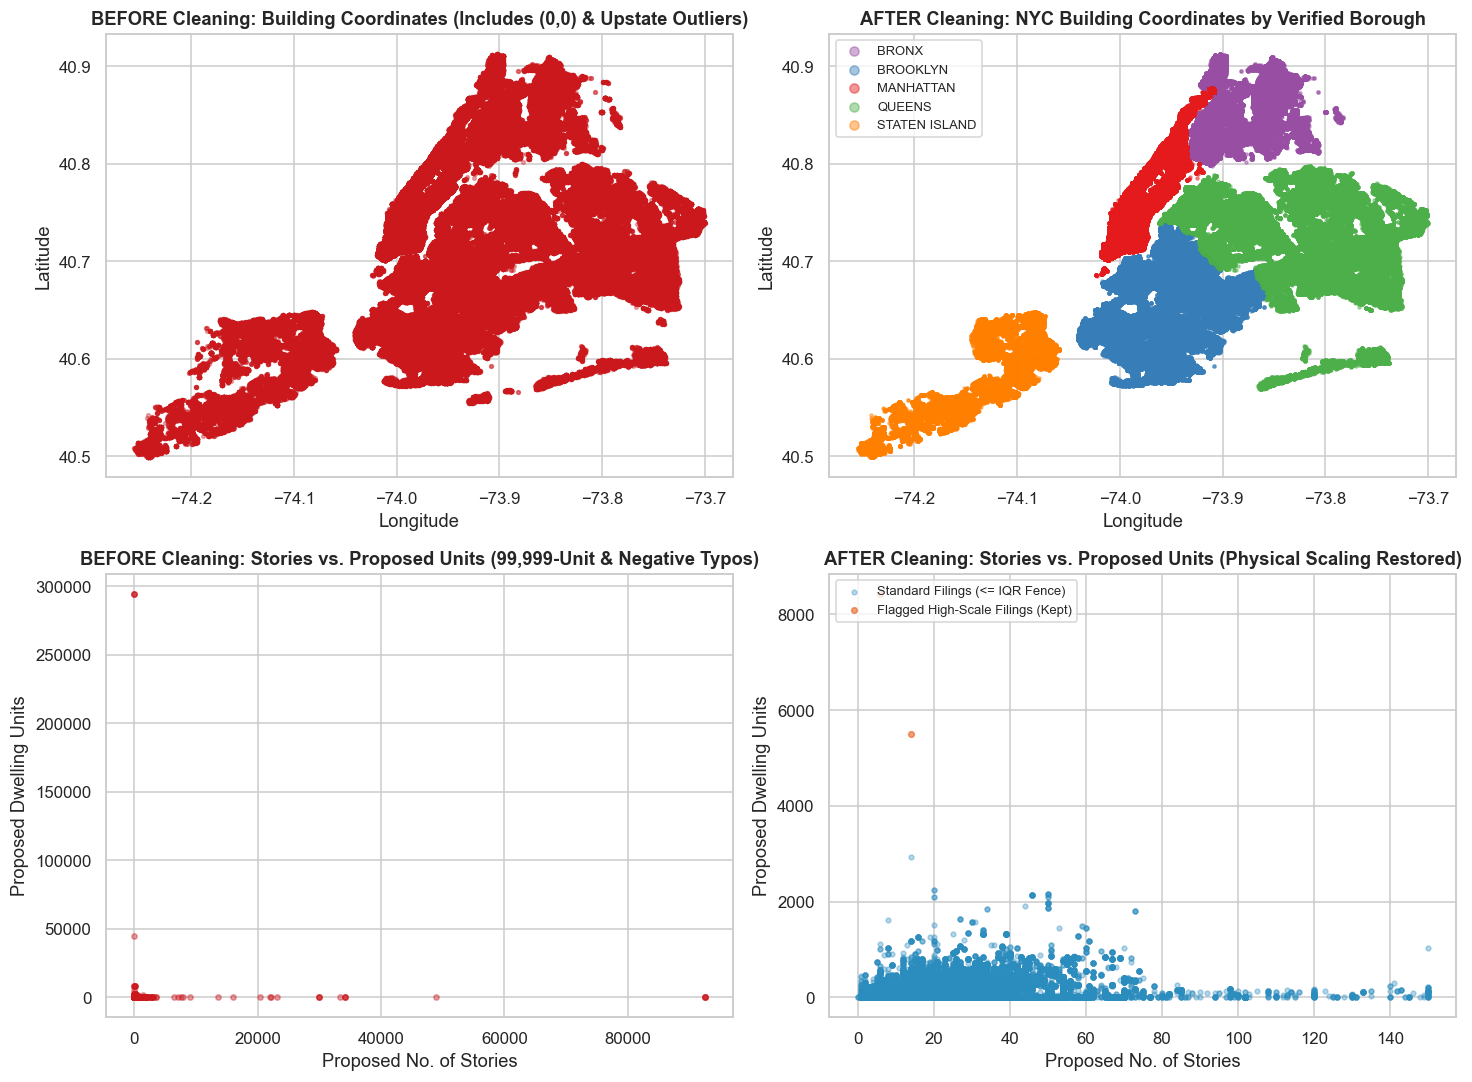

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(13.5, 10))

# Row 1: Spatial coordinates Before vs After
raw_coords = df_raw.dropna(subset=["latitude", "longitude"])
axes[0, 0].scatter(raw_coords["longitude"], raw_coords["latitude"], s=6, alpha=0.35, color="#cb181d")
axes[0, 0].set_title("BEFORE Cleaning: Building Coordinates (Includes (0,0) & Upstate Outliers)")
axes[0, 0].set_xlabel("Longitude")
axes[0, 0].set_ylabel("Latitude")

boro_palette = {
    "MANHATTAN": "#e41a1c",
    "BROOKLYN": "#377eb8",
    "QUEENS": "#4daf4a",
    "BRONX": "#984ea3",
    "STATEN ISLAND": "#ff7f00"
}
for boro, grp in df_housing.groupby("borough"):
    axes[0, 1].scatter(grp["longitude"], grp["latitude"], s=4, alpha=0.45, label=boro, color=boro_palette[boro])
axes[0, 1].set_title("AFTER Cleaning: NYC Building Coordinates by Verified Borough")
axes[0, 1].set_xlabel("Longitude")
axes[0, 1].set_ylabel("Latitude")
axes[0, 1].legend(markerscale=3, fontsize=8.5, loc="upper left")

# Row 2: Proposed Dwelling Units vs Stories Before vs After
axes[1, 0].scatter(
    df_raw["proposed_no_of_stories"],
    df_raw["proposed_dwelling_units"],
    s=12, alpha=0.4, color="#cb181d"
)
axes[1, 0].set_title("BEFORE Cleaning: Stories vs. Proposed Units (99,999-Unit & Negative Typos)")
axes[1, 0].set_xlabel("Proposed No. of Stories")
axes[1, 0].set_ylabel("Proposed Dwelling Units")

normal_rows = df_housing[~df_housing["outlier_proposed_units"]]
outlier_rows = df_housing[df_housing["outlier_proposed_units"]]
axes[1, 1].scatter(
    normal_rows["proposed_no_of_stories"],
    normal_rows["proposed_dwelling_units"],
    s=10, alpha=0.35, color="#2b8cbe", label="Standard Filings (<= IQR Fence)"
)
axes[1, 1].scatter(
    outlier_rows["proposed_no_of_stories"],
    outlier_rows["proposed_dwelling_units"],
    s=14, alpha=0.55, color="#e6550d", label="Flagged High-Scale Filings (Kept)"
)
axes[1, 1].set_title("AFTER Cleaning: Stories vs. Proposed Units (Physical Scaling Restored)")
axes[1, 1].set_xlabel("Proposed No. of Stories")
axes[1, 1].set_ylabel("Proposed Dwelling Units")
axes[1, 1].legend(fontsize=8.5, loc="upper left")

plt.tight_layout()
plt.show()

### 5.3 Data contract verification at row level
Before aggregating to `zip_code × year`, we run strict programmatic assertions on `df_housing` to verify that every Data Contract rule holds.

In [23]:
assert pd.api.types.is_string_dtype(df_housing["zip_code"]), "zip_code must be string/object dtype"
assert df_housing["zip_code"].str.match(r"^\d{5}$").all(), "Every zip_code must be a 5-digit string"
assert pd.api.types.is_integer_dtype(df_housing["year"]), "year must be integer dtype"
assert set(df_housing["year"].unique()).issubset({2022, 2023, 2024, 2025}), "year must be in 2022-2025"
assert set(df_housing["borough"].unique()) == {"BRONX", "BROOKLYN", "MANHATTAN", "QUEENS", "STATEN ISLAND"}, "borough must be uppercase NYC boroughs"
assert all(col == col.lower() and " " not in col for col in df_housing.columns), "All columns must be lowercase_with_underscores"

# Save clean row-level housing dataset to the repository data/clean/ folder
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
df_housing.to_csv("data/clean/housing_clean_row_level.csv", index=False)

print("All row-level Data Contract assertions PASSED! Saved data/clean/housing_clean_row_level.csv.")

All row-level Data Contract assertions PASSED! Saved data/clean/housing_clean_row_level.csv.


## 6. Aggregation to the integration level (ZIP code × year)

To match Member 2's aggregated transportation dataset (`data/clean/transport_clean.csv`), we group `df_housing` by `["zip_code", "year"]` (184 ZIP codes × 4 years = 736 rows). Filing-level metrics use **all filings**; unit metrics use **one `-I1` filing per job** (see the decision cell after the code).

- **`zip_code`:** 5-digit string identifier (assigned from building coordinates via SIRTA 1-NN).
- **`year`:** Integer filing year (`2022`, `2023`, `2024`, `2025`).
- **`borough`:** Modal uppercase borough (`BRONX`, `BROOKLYN`, `MANHATTAN`, `QUEENS`, `STATEN ISLAND`).
- **`filing_count`:** Number of clean job filings (all filings, not distinct jobs) in that `zip_code × year`.
- **`new_construction_filings`:** Count of filings that create a new residential structure or add dwelling units (`net_new_units_row > 0`).
- **`permit_issued_count`:** Count of filings with status `Permit Issued` or `LOC Issued`.
- **`proposed_units_total`:** Sum of `proposed_dwelling_units` over the `-I1` filings (one per job) with credible units.
- **`existing_units_total`:** Sum of `existing_dwelling_units` over the same `-I1` filings.
- **`net_new_units`:** `proposed_units_total − existing_units_total`, i.e. net residential units proposed by jobs first filed in that `zip_code × year`. Unit gains need at least 300 sq ft of construction floor area per new unit to be counted.
- **`initial_cost_total`:** Total estimated construction investment (`initial_cost`, USD) in that `zip_code × year`.
- **`initial_cost_median`:** Median estimated construction cost per filing (USD) in that `zip_code × year`.
- **`total_floor_area`:** Total construction floor area (`total_construction_floor_area`, sq ft) in that `zip_code × year`.
- **`avg_proposed_stories`:** Mean proposed building stories across filings that report it.
- **`avg_proposed_height`:** Mean proposed building height (ft) across filings that report it.
- **`avg_latitude` / `avg_longitude`:** Geographic centroid of construction filings in that `zip_code × year`.
- **`outlier_filing_count` / `outlier_filing_share`:** Count and share of filings flagged by the Tier 2 log-scale IQR rule (`outlier_flag == True`).
- **`is_outlier_zip_year`:** Whether the `zip_code × year` cell itself is an upper-tail IQR outlier in `filing_count` or `net_new_units` (`> Q3 + 1.5 * IQR`).


In [24]:
df_housing["is_permit_active"] = df_housing["filing_status"].isin(["Permit Issued", "LOC Issued"]).astype(int)
df_housing["outlier_flag_int"] = df_housing["outlier_flag"].astype(int)

# A job (e.g. B00552938) can have several filings: -I1 (initial) plus later -P#/-S#/... filings.
# The later filings repeat the job's unit fields (95% identical to the -I1), so summing units over ALL
# filings counts the same building several times. Unit totals therefore use ONE filing per job: the -I1.
df_housing["job_number"] = df_housing["job_filing_number"].str.split("-").str[0]
is_initial = df_housing["job_filing_number"].str.endswith("-I1")

# Credibility check for unit GAINS: a new dwelling unit needs real construction floor area.
# Gains with < 300 sq ft of total_construction_floor_area per new unit (e.g. +1,455 units on a 100 sq ft,
# $1,000 alteration) are building-level descriptors, not new supply, and are left out of the unit sums.
MIN_SQFT_PER_NEW_UNIT = 300
net_row = df_housing["net_new_units_row"]
units_credible = (net_row <= 0) | (df_housing["total_construction_floor_area"] >= MIN_SQFT_PER_NEW_UNIT * net_row)
units_mask = is_initial & df_housing["proposed_dwelling_units"].notna() & units_credible

print(f"Filings: {len(df_housing):,} | distinct jobs: {df_housing['job_number'].nunique():,} | "
      f"-I1 filings: {is_initial.sum():,}")
print(f"-I1 filings used for unit totals: {units_mask.sum():,} "
      f"(excluded {(is_initial & df_housing['proposed_dwelling_units'].isna()).sum():,} with blank proposed units, "
      f"{(is_initial & df_housing['proposed_dwelling_units'].notna() & ~units_credible).sum():,} implausible gains "
      f"< {MIN_SQFT_PER_NEW_UNIT} sq ft per new unit)")

# (1) Filing-level metrics: computed from ALL filings
df_housing_agg = (
    df_housing.groupby(["zip_code", "year"], as_index=False)
    .agg(
        borough=("borough", lambda s: s.mode().iloc[0]),
        filing_count=("job_filing_number", "count"),
        new_construction_filings=("is_new_construction", "sum"),
        permit_issued_count=("is_permit_active", "sum"),
        initial_cost_total=("initial_cost", "sum"),
        initial_cost_median=("initial_cost", "median"),
        total_floor_area=("total_construction_floor_area", "sum"),
        avg_proposed_stories=("proposed_no_of_stories", "mean"),
        avg_proposed_height=("proposed_height", "mean"),
        avg_latitude=("latitude", "mean"),
        avg_longitude=("longitude", "mean"),
        outlier_filing_count=("outlier_flag_int", "sum"),
        outlier_filing_share=("outlier_flag_int", "mean"),
    )
)

# (2) Unit metrics: ONE filing per job (-I1), so proposed - existing = net exactly
df_units = (
    df_housing[units_mask].groupby(["zip_code", "year"], as_index=False)
    .agg(
        proposed_units_total=("proposed_dwelling_units", "sum"),
        existing_units_total=("existing_dwelling_units", "sum"),
        net_new_units=("net_new_units_row", "sum"),
    )
)
df_housing_agg = df_housing_agg.merge(df_units, on=["zip_code", "year"], how="left")
unit_cols = ["proposed_units_total", "existing_units_total", "net_new_units"]
df_housing_agg[unit_cols] = df_housing_agg[unit_cols].fillna(0.0)   # no -I1 filing in that cell = 0 units

# Keep the original exported column order (unchanged data contract)
df_housing_agg = df_housing_agg[[
    "zip_code", "year", "borough", "filing_count", "new_construction_filings", "permit_issued_count",
    "proposed_units_total", "existing_units_total", "net_new_units", "initial_cost_total",
    "initial_cost_median", "total_floor_area", "avg_proposed_stories", "avg_proposed_height",
    "avg_latitude", "avg_longitude", "outlier_filing_count", "outlier_filing_share",
]]

# Round continuous aggregates for clean presentation
df_housing_agg["initial_cost_total"] = df_housing_agg["initial_cost_total"].round(2)
df_housing_agg["initial_cost_median"] = df_housing_agg["initial_cost_median"].round(2)
df_housing_agg["avg_proposed_stories"] = df_housing_agg["avg_proposed_stories"].round(2)
df_housing_agg["avg_proposed_height"] = df_housing_agg["avg_proposed_height"].round(2)
df_housing_agg["avg_latitude"] = df_housing_agg["avg_latitude"].round(6)
df_housing_agg["avg_longitude"] = df_housing_agg["avg_longitude"].round(6)
df_housing_agg["outlier_filing_share"] = df_housing_agg["outlier_filing_share"].round(4)

# Compute cell-level IQR outlier flag (`is_outlier_zip_year`)
q1_fc, q3_fc = df_housing_agg["filing_count"].quantile([0.25, 0.75])
iqr_fc = q3_fc - q1_fc
q1_nu, q3_nu = df_housing_agg["net_new_units"].quantile([0.25, 0.75])
iqr_nu = q3_nu - q1_nu

df_housing_agg["is_outlier_zip_year"] = (
    (df_housing_agg["filing_count"] > (q3_fc + 1.5 * iqr_fc)) |
    (df_housing_agg["net_new_units"] > (q3_nu + 1.5 * iqr_nu))
)

# Ensure zip_code is a 5-digit string and year is integer
df_housing_agg["zip_code"] = df_housing_agg["zip_code"].astype(str).str.zfill(5)
df_housing_agg["year"] = df_housing_agg["year"].astype(int)

# Sanity checks on the unit totals
assert (df_housing_agg["proposed_units_total"] - df_housing_agg["existing_units_total"]
        - df_housing_agg["net_new_units"]).abs().max() < 1e-6, "net_new_units must equal proposed - existing"
print("\nCity-wide net_new_units per year (one -I1 filing per job):")
print(df_housing_agg.groupby("year")["net_new_units"].sum().map("{:,.0f}".format).to_string())

# Export final aggregated dataset to the repository data/clean/housing_clean.csv
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
df_housing_agg.to_csv("data/clean/housing_clean.csv", index=False)

print(f"\nExported aggregated housing dataset to 'data/clean/housing_clean.csv': {df_housing_agg.shape[0]:,} rows × {df_housing_agg.shape[1]} columns")
print(f"Unique ZIP codes covered: {df_housing_agg['zip_code'].nunique()} | Years covered: {sorted(df_housing_agg['year'].unique())}")
print("\n=== EXACT EXPORTED COLUMN NAMES FOR TEAM INTEGRATION ===")
for idx, col_name in enumerate(df_housing_agg.columns, 1):
    print(f"  {idx:2d}. {col_name} ({df_housing_agg[col_name].dtype})")

df_housing_agg.head(10)


Filings: 589,439 | distinct jobs: 341,051 | -I1 filings: 312,654
-I1 filings used for unit totals: 270,038 (excluded 38,027 with blank proposed units, 4,589 implausible gains < 300 sq ft per new unit)

City-wide net_new_units per year (one -I1 filing per job):
year
2022    101,402
2023     57,991
2024     54,355
2025     82,351

Exported aggregated housing dataset to 'data/clean/housing_clean.csv': 736 rows × 19 columns
Unique ZIP codes covered: 184 | Years covered: [np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]

=== EXACT EXPORTED COLUMN NAMES FOR TEAM INTEGRATION ===
   1. zip_code (str)
   2. year (int64)
   3. borough (str)
   4. filing_count (int64)
   5. new_construction_filings (int64)
   6. permit_issued_count (int64)
   7. proposed_units_total (float64)
   8. existing_units_total (float64)
   9. net_new_units (float64)
  10. initial_cost_total (float64)
  11. initial_cost_median (float64)
  12. total_floor_area (float64)
  13. avg_proposed_stories (float64)
 

,zip_code,year,borough,filing_count,new_construction_filings,permit_issued_count,proposed_units_total,existing_units_total,net_new_units,initial_cost_total,initial_cost_median,total_floor_area,avg_proposed_stories,avg_proposed_height,avg_latitude,avg_longitude,outlier_filing_count,outlier_filing_share,is_outlier_zip_year
0,10001,2022,MANHATTAN,2801,46,1359,78207.0,78049.0,158.0,1.340664e+09,25000.00,1.059316e+08,25.52,317.90,40.750575,-73.995443,106,0.0378,True
1,10001,2023,MANHATTAN,2919,34,1338,69811.0,69668.0,143.0,1.879282e+09,35891.15,7.919937e+07,28.71,384.77,40.750694,-73.995189,90,0.0308,True
2,10001,2024,MANHATTAN,2906,41,1353,40181.0,40236.0,-55.0,1.205659e+09,38155.00,6.231341e+07,32.25,473.73,40.750665,-73.995778,64,0.0220,True
3,10001,2025,MANHATTAN,2800,95,957,39359.0,39655.0,-296.0,1.347289e+09,37500.00,5.003406e+07,27.92,393.87,40.750524,-73.994984,49,0.0175,True
4,10002,2022,MANHATTAN,1332,66,590,74120.0,73391.0,729.0,3.431780e+08,20000.00,1.178515e+08,10.43,102.56,40.717390,-73.988371,64,0.0480,False
5,10002,2023,MANHATTAN,1295,58,584,61165.0,60917.0,248.0,2.283181e+08,16100.00,2.430794e+07,9.96,103.87,40.717005,-73.988200,26,0.0201,False
6,10002,2024,MANHATTAN,1240,74,461,49695.0,50519.0,-824.0,1.601148e+08,16875.00,1.428209e+08,9.42,94.33,40.717355,-73.988562,19,0.0153,False
7,10002,2025,MANHATTAN,1347,78,362,40070.0,40122.0,-52.0,1.897249e+08,21080.00,1.928887e+07,9.22,86.85,40.717584,-73.989082,9,0.0067,False
8,10003,2022,MANHATTAN,2819,39,1457,119627.0,119369.0,258.0,6.198392e+08,30000.00,3.515908e+07,11.20,123.22,40.733430,-73.990081,57,0.0202,True
9,10003,2023,MANHATTAN,2462,78,1107,83619.0,84035.0,-416.0,5.308841e+08,30000.00,3.242086e+07,11.61,123.02,40.733629,-73.990130,46,0.0187,True


**Decision — unit totals use one filing per job (the `-I1` filing):**
- **The problem:** a DOB NOW *job* (e.g. `B00552938`) is made up of several *filings*: the initial `-I1` plus later `-P#`, `-S#`, `-A#`… filings. About 95% of those later filings simply repeat the job's `existing_dwelling_units` / `proposed_dwelling_units`. Summing units over every filing therefore counted the same building several times; one job with 40 filings counted its units 40 times. That is why `proposed_units_total` reached six figures for a single ZIP code.
- **Why `-I1` rather than "latest filing per job":** (1) every job has exactly one `-I1`, so the choice is unambiguous and needs no tie-breaking on dates. (2) The `-I1` `filing_date` is when the project first entered the pipeline. About 45% of later filings fall in a later calendar year than their `-I1`, so using the latest filing would move many jobs to the year of their last amendment and blur the year-by-year comparison with crashes. (3) Jobs with no `-I1` in the 2022–2025 extract were opened before 2022 (their job numbers are much older). Leaving their units out keeps pre-2022 projects out of the 2022–2025 totals. The trade-off is that a later amendment that changes the unit count is not reflected, but only about 5% of later filings change units at all.
- **Units credibility check:** some `-I1` alteration jobs report the *whole building's* units as "proposed" with 0 existing, e.g. +1,455 units on a \$1,000 job with 100 sq ft of work. A unit **gain** is only counted if the job has at least **300 sq ft of construction floor area per new unit**, which is roughly the smallest legal NYC apartment. The filing still counts in `filing_count`; only its unit fields are left out. Unit losses are not filtered, because demolitions and unit mergers do not need new floor area. `proposed_units_total`, `existing_units_total` and `net_new_units` are all computed on this same set of filings, so `net_new_units = proposed − existing` holds exactly (asserted in the cell).
- **Unchanged:** `filing_count` and every other filing-level metric still use all filings. The exported column names and order are identical. The printed "distinct jobs" figure gives the job count without adding a new column to the data contract.


In [25]:
# Summary statistics of the aggregated ZIP × year dataset
df_housing_agg.describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]].round(2)

,count,mean,std,min,25%,50%,75%,max
year,736.0,2.023500e+03,1.120000e+00,2022.00,2022.75,2.023500e+03,2.024250e+03,2.025000e+03
filing_count,736.0,8.008700e+02,6.519400e+02,4.00,340.75,6.310000e+02,1.029500e+03,3.592000e+03
new_construction_filings,736.0,1.007400e+02,9.600000e+01,0.00,30.00,6.700000e+01,1.480000e+02,5.520000e+02
permit_issued_count,736.0,3.129000e+02,2.926400e+02,0.00,120.00,2.330000e+02,3.782500e+02,1.962000e+03
proposed_units_total,736.0,1.502049e+04,2.505072e+04,0.00,1294.00,6.046500e+03,1.552050e+04,1.849550e+05
existing_units_total,736.0,1.461818e+04,2.501928e+04,0.00,1163.75,5.629500e+03,1.445450e+04,1.846120e+05
net_new_units,736.0,4.023100e+02,1.038740e+03,-4133.00,0.00,5.750000e+01,5.142500e+02,7.853000e+03
initial_cost_total,736.0,2.186101e+08,2.813698e+08,16000.00,52947987.22,1.289780e+08,2.616925e+08,2.223702e+09
initial_cost_median,736.0,2.598529e+04,1.417966e+04,1000.00,18346.88,2.498300e+04,3.000000e+04,1.400000e+05
total_floor_area,736.0,1.707500e+07,4.096085e+07,2131.80,2443674.88,7.097717e+06,1.862180e+07,7.858987e+08


## 7. Research questions and visualizations

To demonstrate how our cleaned housing dataset (`data/clean/housing_clean.csv`) integrates with Member 2's traffic safety dataset (`data/clean/transport_clean.csv`) at the `zip_code × year` grain, we perform the inner merge on `["zip_code", "year"]` to produce `integrated_dataset.csv` and investigate two cross-domain research questions.

### Question 1: Residential Expansion Intensity vs. Severe Traffic Collisions Across Boroughs
> **Research Question 1:** *Do NYC ZIP codes experiencing intense residential construction and net new housing unit growth (`filing_count`, `net_new_units`) between 2022 and 2025 also experience elevated severe and fatal traffic collisions (`crash_count`, `severe_injuries_total`), and how does this relationship differ between high-density boroughs (Brooklyn, Queens, Manhattan, Bronx) and car-dependent Staten Island?*

**Why this matters for the Data Story:** Active construction zones introduce heavy truck traffic, lane closures, sidewalk sheds, and temporary pedestrian detours, while completed residential units expand neighborhood population and multimodal street activity. Understanding where rapid housing growth coincides with high severe crash volumes identifies priority neighborhoods for Vision Zero street redesigns.

Integrated dataset ('integrated_dataset.csv') shape: 701 ZIP×year cells × 27 columns


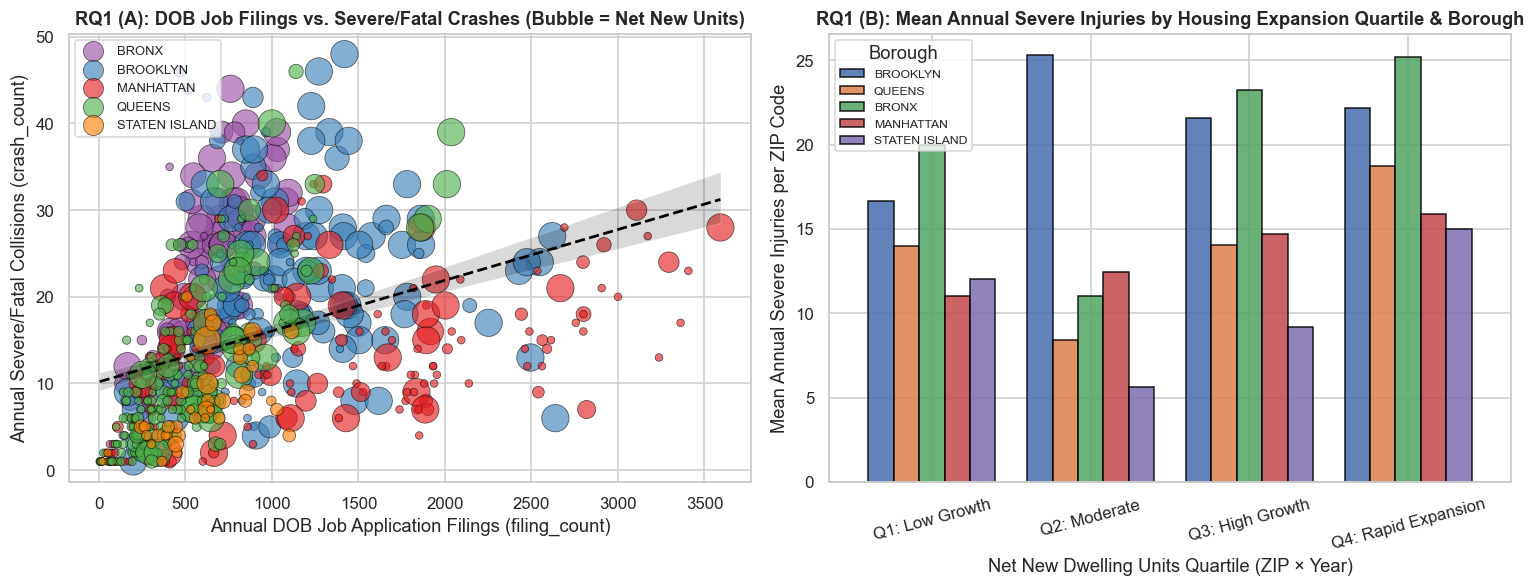

In [26]:
# Merge Member 1 (housing_clean.csv) and Member 2 (transport_clean.csv) on (zip_code, year)
transport_paths = ["data/clean/transport_clean.csv", "../data/clean/transport_clean.csv", "transport_clean.csv"]
transport_path = next((p for p in transport_paths if os.path.exists(p)), None)
df_transport_agg = pd.read_csv(transport_path, dtype={"zip_code": str})
df_transport_agg["zip_code"] = df_transport_agg["zip_code"].str.zfill(5)

df_integrated = pd.merge(
    df_housing_agg,
    df_transport_agg.drop(columns=["borough", "avg_latitude", "avg_longitude"], errors="ignore"),
    on=["zip_code", "year"],
    how="inner",
    suffixes=("_housing", "_transport")
)

# Save integrated_dataset.csv to the repository data/clean/ folder
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
df_integrated.to_csv("data/clean/integrated_dataset.csv", index=False)

print(f"Integrated dataset ('integrated_dataset.csv') shape: {df_integrated.shape[0]:,} ZIP×year cells × {df_integrated.shape[1]} columns")

# Visualization 1: Joint Multi-Panel Analysis for Research Question 1
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

boro_colors = {
    "MANHATTAN": "#e41a1c",
    "BROOKLYN": "#377eb8",
    "QUEENS": "#4daf4a",
    "BRONX": "#984ea3",
    "STATEN ISLAND": "#ff7f00"
}

# Panel A: Bubble Scatter of Construction Filing Volume vs. Severe/Fatal Crash Count
for boro, grp in df_integrated.groupby("borough"):
    sizes = np.clip(grp["net_new_units"] * 0.45 + 25, 25, 320)
    axes[0].scatter(
        grp["filing_count"], grp["crash_count"],
        s=sizes, alpha=0.62, color=boro_colors[boro], edgecolors="black", linewidth=0.5, label=boro
    )

# Add linear trend line & Pearson correlation
r_val = df_integrated["filing_count"].corr(df_integrated["crash_count"])
sns.regplot(
    data=df_integrated, x="filing_count", y="crash_count",
    scatter=False, ax=axes[0], color="black", line_kws={"linestyle": "--", "linewidth": 1.8, "label": f"OLS Trend (r = {r_val:.2f})"}
)
axes[0].set_title("RQ1 (A): DOB Job Filings vs. Severe/Fatal Crashes (Bubble = Net New Units)")
axes[0].set_xlabel("Annual DOB Job Application Filings (filing_count)")
axes[0].set_ylabel("Annual Severe/Fatal Collisions (crash_count)")
axes[0].legend(fontsize=8.5, loc="upper left")

# Panel B: Severe Injuries Across Housing Expansion Tiers by Borough
df_integrated["growth_tier"] = pd.qcut(
    df_integrated["net_new_units"].rank(method="first"),
    q=4,
    labels=["Q1: Low Growth", "Q2: Moderate", "Q3: High Growth", "Q4: Rapid Expansion"]
)
tier_summary = (
    df_integrated.groupby(["growth_tier", "borough"], observed=False)["severe_injuries_total"]
    .mean()
    .unstack()
)
tier_summary[["BROOKLYN", "QUEENS", "BRONX", "MANHATTAN", "STATEN ISLAND"]].plot(
    kind="bar", ax=axes[1], width=0.8, edgecolor="black", alpha=0.88
)
axes[1].set_title("RQ1 (B): Mean Annual Severe Injuries by Housing Expansion Quartile & Borough")
axes[1].set_xlabel("Net New Dwelling Units Quartile (ZIP × Year)")
axes[1].set_ylabel("Mean Annual Severe Injuries per ZIP Code")
axes[1].tick_params(axis="x", rotation=15)
axes[1].legend(title="Borough", fontsize=8)

plt.tight_layout()
plt.show()

**Interpretation of Visualization 1:**
- **Moderate positive association, not causation ($r = 0.38$):** across the 701 matched `zip_code × year` cells, ZIP-years with more DOB filings (`filing_count`) also tend to have more severe/fatal crashes (`crash_count`). The rank correlation is stronger (Spearman ≈ 0.59), so the relationship is fairly consistent in direction but noisy and not linear. Within boroughs it is strongest in the Bronx ($r ≈ 0.78$) and Queens (≈ 0.74), moderate in Staten Island (≈ 0.55) and Manhattan (≈ 0.50), and weak in Brooklyn (≈ 0.18).
- **Housing growth quartiles (Panel B):** mean severe injuries per ZIP-year are 13.1 in Q1 (net unit losses up to 0 units), 10.5 in Q2 (0–68 units), 16.6 in Q3 (69–558 units) and 21.3 in Q4 (568–7,853 units). Q4 is highest, but the pattern is not monotonic. Within each of the four large boroughs, Q4 ZIP-years average more severe injuries than Q1: Bronx 25.2 vs. 20.0, Brooklyn 22.2 vs. 16.7, Queens 18.7 vs. 14.0, Manhattan 15.9 vs. 11.0. Staten Island has only one ZIP-year in Q1 and one in Q4, so its bars cannot be interpreted.
- **Caveats:** the quartiles mix boroughs very unevenly (Q1 is mostly Manhattan, Q2 mostly Queens). Larger, busier ZIP codes have both more construction and more traffic, so ZIP size, population and road network are likely confounders. The same ZIP appears up to four times, so the cells are not independent. These results describe where construction and severe crashes co-occur. They do **not** show that construction causes crashes.

---

### Question 2: Temporal Evolution of Vertical Construction Investment and Crash Severity / Nighttime Risk (2022–2025)
> **Research Question 2:** *How have major construction capital investment (`initial_cost_total`) and new residential construction filings (`new_construction_filings`) co-evolved with severe crash rates (`severe_per_crash`) and nighttime collision shares (`night_crash_share`) across NYC from 2022 to 2025, and which geographic corridors represent simultaneous high-development / high-crash-risk hotspots?*


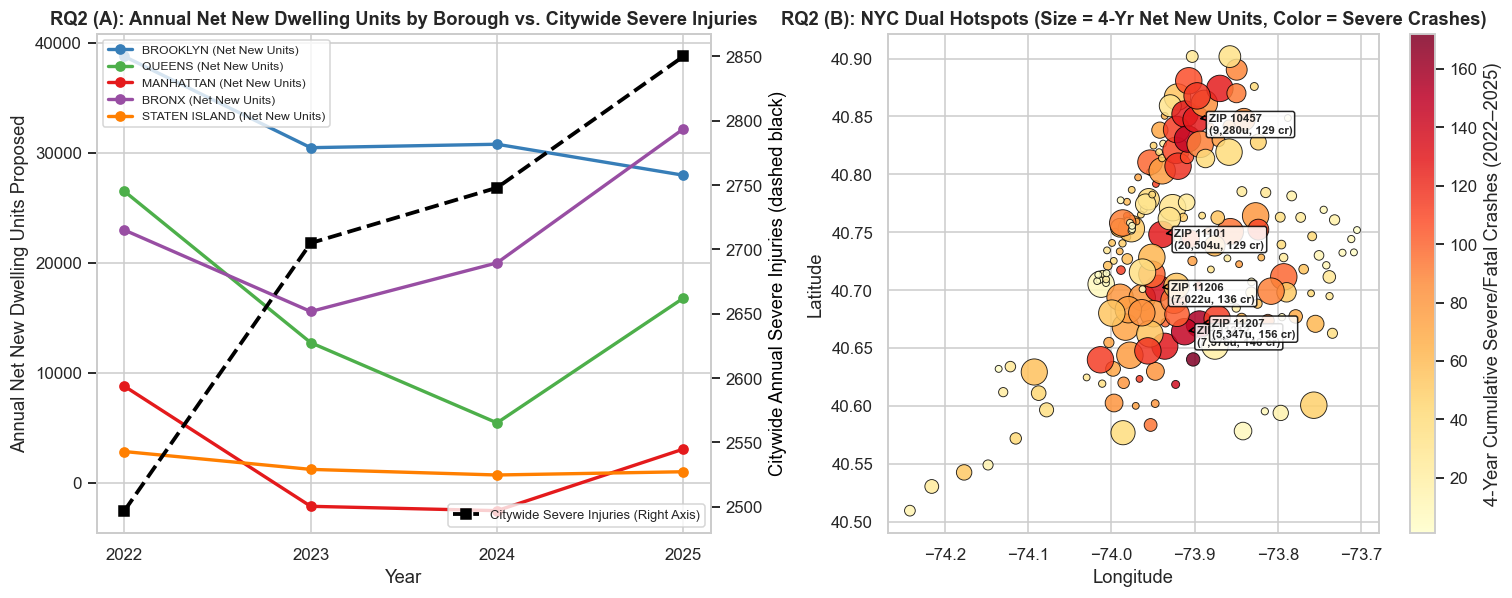

In [27]:
# Visualization 2: Temporal Trajectories (2022-2025) & Spatial Risk Quadrant Map
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))

# Panel A: Borough-level temporal trends (2022-2025) of Net New Units vs Severe Injuries
yr_boro = (
    df_integrated.groupby(["year", "borough"])
    .agg(
        net_new_units=("net_new_units", "sum"),
        new_const=("new_construction_filings", "sum"),
        severe_inj=("severe_injuries_total", "sum"),
        cost_millions=("initial_cost_total", lambda s: s.sum() / 1e6)
    )
    .reset_index()
)

for boro in ["BROOKLYN", "QUEENS", "MANHATTAN", "BRONX", "STATEN ISLAND"]:
    sub = yr_boro[yr_boro["borough"] == boro]
    axes[0].plot(
        sub["year"], sub["net_new_units"],
        marker="o", linewidth=2.2, label=f"{boro} (Net New Units)", color=boro_colors[boro]
    )

ax0_twin = axes[0].twinx()
yr_total_sev = df_integrated.groupby("year")["severe_injuries_total"].sum()
ax0_twin.plot(
    yr_total_sev.index, yr_total_sev.values,
    color="black", linestyle="--", marker="s", linewidth=2.5, label="Citywide Severe Injuries (Right Axis)"
)
ax0_twin.set_ylabel("Citywide Annual Severe Injuries (dashed black)", color="black")
ax0_twin.grid(False)

axes[0].set_xticks([2022, 2023, 2024, 2025])
axes[0].set_title("RQ2 (A): Annual Net New Dwelling Units by Borough vs. Citywide Severe Injuries")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Annual Net New Dwelling Units Proposed")
axes[0].legend(loc="upper left", fontsize=8)
ax0_twin.legend(loc="lower right", fontsize=8.5)

# Panel B: Spatial Hotspot Map of 4-Year Cumulative Housing Growth & Crash Risk per ZIP Code
zip_4yr = (
    df_integrated.groupby(["zip_code", "borough"], as_index=False)
    .agg(
        lat=("avg_latitude", "mean"),
        lon=("avg_longitude", "mean"),
        total_filings=("filing_count", "sum"),
        total_net_units=("net_new_units", "sum"),
        total_crashes=("crash_count", "sum"),
        mean_night_share=("night_crash_share", "mean")
    )
)

sc = axes[1].scatter(
    zip_4yr["lon"], zip_4yr["lat"],
    c=zip_4yr["total_crashes"],
    s=np.clip(zip_4yr["total_net_units"] * 0.12 + 20, 20, 300),
    cmap="YlOrRd", alpha=0.85, edgecolors="black", linewidth=0.6
)
cbar = plt.colorbar(sc, ax=axes[1])
cbar.set_label("4-Year Cumulative Severe/Fatal Crashes (2022–2025)")

# Annotate top 5 combined hotspot ZIP codes
zip_4yr["hotspot_score"] = zip_4yr["total_net_units"].rank(pct=True) + zip_4yr["total_crashes"].rank(pct=True)
for _, r in zip_4yr.nlargest(5, "hotspot_score").iterrows():
    axes[1].annotate(
        f"ZIP {r['zip_code']}\n({int(r['total_net_units']):,}u, {int(r['total_crashes'])} cr)",
        xy=(r["lon"], r["lat"]),
        xytext=(r["lon"] + 0.015, r["lat"] - 0.012),
        fontsize=7.5, fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="black", alpha=0.85),
        arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=0.15", color="black")
    )

axes[1].set_title("RQ2 (B): NYC Dual Hotspots (Size = 4-Yr Net New Units, Color = Severe Crashes)")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")

plt.tight_layout()
plt.show()

**Interpretation of Visualization 2:**
- **Net new units did not peak in 2023–24 (Panel A):** summed over the matched ZIP-years, net new units proposed are highest in **2022 (≈ 99,800)**, lowest in **2023 (≈ 57,800) and 2024 (≈ 54,400)**, and rise again in **2025 (≈ 80,900)**. Brooklyn contributes the most units in 2022–2024 (≈ 30,000–39,000 a year), and the Bronx is largest in 2025 (≈ 32,200). Queens falls from ≈ 26,500 (2022) to ≈ 5,400 (2024) before recovering to ≈ 16,800. Manhattan is slightly negative in 2023 and 2024 (more units removed than added in those filings).
- **Severe injuries move differently:** citywide severe injuries in the matched ZIPs rise every year, from 2,497 (2022) to 2,705, 2,748 and 2,850 (2025), +14% overall. Net new units fell from 2022 to 2024 while injuries rose, so the two series do **not** track each other year to year.
- **Other RQ2 variables (from the integrated table, not plotted):** filings rise from ≈ 138,000 to ≈ 155,000, `new_construction_filings` from ≈ 15,700 to ≈ 22,100 and `initial_cost_total` from ≈ \$33B to ≈ \$50B between 2022 and 2025. Mean `severe_per_crash` stays close to 1.0 (0.99–1.04) and `night_crash_share` stays between 23% and 25%. Construction investment grew while crash severity and night-time share stayed roughly flat.
- **Dual hotspots (Panel B):** ranking ZIPs by 4-year net new units plus 4-year severe/fatal crashes gives these top five:

  | ZIP | Area | Net new units | Severe/fatal crashes |
  | :--- | :--- | ---: | ---: |
  | `11101` | Long Island City, Queens | 20,504 | 129 |
  | `11212` | Brownsville, Brooklyn | 7,576 | 146 |
  | `10457` | Tremont area, Bronx | 9,280 | 129 |
  | `11206` | Williamsburg / Bushwick, Brooklyn | 7,022 | 136 |
  | `11207` | East New York, Brooklyn | 5,347 | 156 |

  These are places where high housing growth and high crash counts **coincide**. They are candidates for closer review (e.g. joint DOT/DOB attention), not evidence that one causes the other. Bubble sizes are capped in the plot, so the size differences between the largest ZIPs are compressed.


## 8. Prompts used, dataset links, and contribution statement

### 8.1 Prompts used during development
| Stage | Prompt Summary | How Output Was Verified & Adapted |
| :--- | :--- | :--- |
| **SoQL Extraction** | *"Construct a Socrata SoQL query in Python for `w9ak-ipjd.csv` filtering `filing_date` between 2022 and 2025 and selecting core building, unit, cost, coordinate, and sparse energy columns."* | Verified column names against `DOB_NOW_Build_Job_Application_Filings_Data_Dictionary.xlsx` and added offline CSV fallback handling. |
| **Owner ZIP Audit & 1-NN Matching** | *"Show how to audit the raw `zip` column in H5 against `borough` and integrate `assign_building_zip` from `assign_zip_from_sirta.py` using Member 2's row-level SIRTA crashes."* | Verified that `assign_building_zip` assigned 5-digit string ZIPs within `0.01°` (~1 km) and documented the ~9–10% boundary error rate and missing coordinate counts. |
| **Outlier Strategy** | *"Design a two-tier outlier rule for DOB NOW job filings that removes impossible data-entry typos (e.g., $350M on a 1-3 family home) while flagging and retaining legitimate high-rise developments."* | Validated thresholds against NYC building height limits (<2,000 ft) and IQR fences on `initial_cost`, `proposed_dwelling_units`, and `total_construction_floor_area`. |
| **Cross-Domain Visualizations** | *"Propose 2 research questions and 2 multi-panel visualizations joining `housing_clean.csv` and `transport_clean.csv` on `zip_code` and `year`."* | Executed the merge to create `integrated_dataset.csv` and verified all plots render with clear titles, units, and legends. |

### 8.2 Dataset and reference links
- **Primary Housing Dataset (H5 — DOB NOW: Build – Job Application Filings):**  
  - NYC Open Data Portal: [https://data.cityofnewyork.us/Housing-Development/DOB-NOW-Build-Job-Application-Filings/w9ak-ipjd](https://data.cityofnewyork.us/Housing-Development/DOB-NOW-Build-Job-Application-Filings/w9ak-ipjd)  
  - Socrata CSV API Endpoint: [https://data.cityofnewyork.us/resource/w9ak-ipjd.csv](https://data.cityofnewyork.us/resource/w9ak-ipjd.csv)  
  - Official Data Dictionary: `DOB_NOW_Build_Job_Application_Filings_Data_Dictionary.xlsx` (NYC Department of Buildings)
- **Partner Transportation Dataset (T2 — Motor Vehicle Collisions with Killed or Seriously Injured / SIRTA):**  
  - NYC Open Data Portal: [https://data.cityofnewyork.us/Public-Safety/Motor-Vehicle-Collisions-With-Killed-or-Seriously-/xeqp-qz8h](https://data.cityofnewyork.us/Public-Safety/Motor-Vehicle-Collisions-With-Killed-or-Seriously-/xeqp-qz8h)  
  - Socrata CSV API Endpoint: [https://data.cityofnewyork.us/resource/xeqp-qz8h.csv](https://data.cityofnewyork.us/resource/xeqp-qz8h.csv)
- **Technical Documentation:**  
  - Socrata SoQL Query Clauses (`$select`, `$where`, `$limit`): [https://dev.socrata.com/docs/queries/](https://dev.socrata.com/docs/queries/)  
  - US Census Bureau ZIP Code Tabulation Areas (ZCTAs): [https://www.census.gov/programs-surveys/geography/guidance/geo-areas/zctas.html](https://www.census.gov/programs-surveys/geography/guidance/geo-areas/zctas.html)

### 8.3 Contribution statement
- **Member 1 (Argon — Housing Domain):** Authored `notebooks/Member1_Housing.ipynb`; audited the 72-column DOB NOW H5 schema; implemented the SoQL extraction and EDA pipeline; empirically proved the owner `zip` business-address discrepancy and applied `assign_building_zip` from `assign_zip_from_sirta.py` against Member 2's geocoded crash points; executed domain validation and two-tier IQR/domain outlier handling; aggregated the housing metrics to `zip_code × year` (`data/clean/housing_clean.csv`); and created the post-integration visualizations on `integrated_dataset.csv`.